<a href="https://colab.research.google.com/github/vishvaragavanp2024aiml-lang/241501249-Deep-Learning-Lab/blob/main/Deep_Learning_Mini_Project_249.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Device: cpu | AMP: False | torch 2.11.0+cpu | QUICK_MODE=True

EXPERIMENT 1: Three-layer neural network from scratch (NumPy, no autograd)
Aim            : Implement forward/backward propagation manually and train with mini-batch gradient descent.
Dataset        : MNIST (10k train / 2k test subset)
Model          : 784-128-64-10 MLP, ReLU hidden, softmax + cross-entropy
Hyperparameters: epochs=25, batch=128, lr=0.1, He init


100%|██████████| 9.91M/9.91M [00:00<00:00, 52.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.53MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 13.7MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.69MB/s]


  epoch 01/25 | train loss 0.5940 acc 81.27% | test loss 0.5889 acc 81.70%
  epoch 02/25 | train loss 0.2530 acc 92.18% | test loss 0.2350 acc 93.25%
  epoch 03/25 | train loss 0.1746 acc 94.66% | test loss 0.2455 acc 93.00%
  epoch 04/25 | train loss 0.1343 acc 95.98% | test loss 0.2441 acc 92.55%
  epoch 05/25 | train loss 0.1082 acc 96.83% | test loss 0.1744 acc 95.30%
  epoch 06/25 | train loss 0.0832 acc 97.82% | test loss 0.1875 acc 94.50%
  epoch 07/25 | train loss 0.0666 acc 98.13% | test loss 0.1676 acc 95.15%
  epoch 08/25 | train loss 0.0536 acc 98.72% | test loss 0.1635 acc 95.10%
  epoch 09/25 | train loss 0.0427 acc 99.06% | test loss 0.1752 acc 95.40%
  epoch 10/25 | train loss 0.0340 acc 99.39% | test loss 0.1692 acc 95.30%
  epoch 11/25 | train loss 0.0274 acc 99.56% | test loss 0.1760 acc 95.30%
  epoch 12/25 | train loss 0.0234 acc 99.72% | test loss 0.1694 acc 95.50%
  epoch 13/25 | train loss 0.0197 acc 99.76% | test loss 0.1789 acc 95.15%
  epoch 14/25 | train los

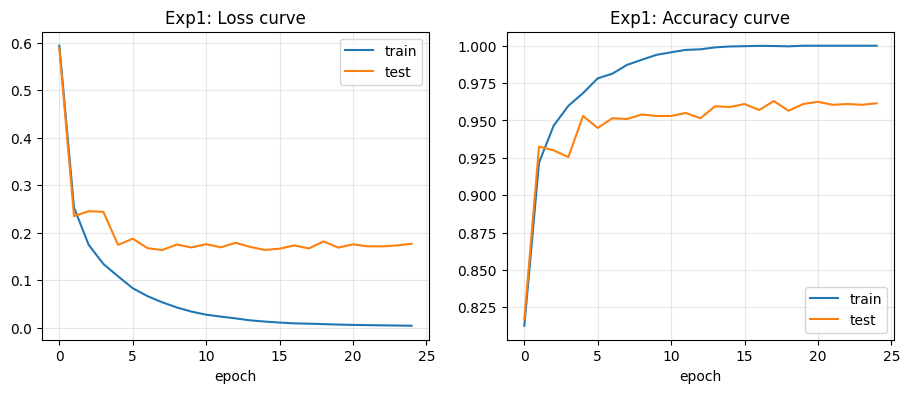

  [saved] ./outputs/exp1_predictions.png


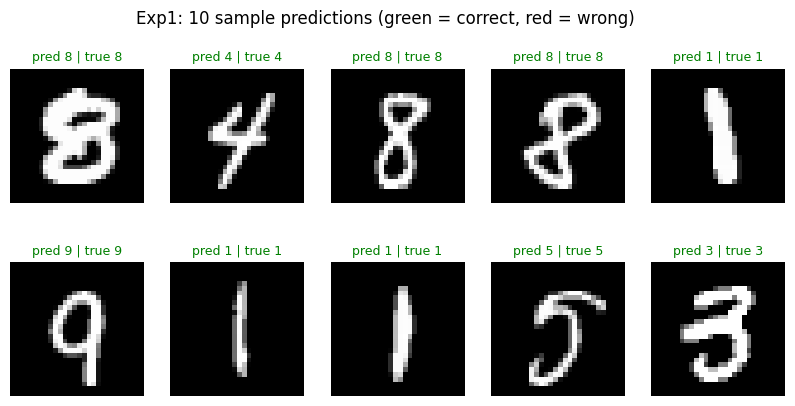

  [saved] ./outputs/exp1_confusion.png


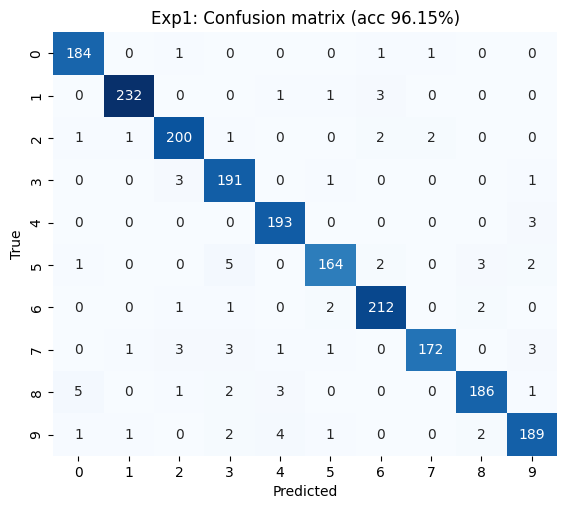


  Observations/Inference: the loss fell from 0.594 to 0.004 and test accuracy reached 96.15% with only manual gradients, which confirms the backprop equations are correct. Train/test accuracy gap = 3.85 pts. Most frequent error: '5' misclassified as '3' (5 times).

[Exp 1] finished in 11.0s

EXPERIMENT 2: MLP on Iris - effect of depth and activation function
Aim            : Compare MLPs with 1/2/3 hidden layers and ReLU/Tanh/Sigmoid activations.
Dataset        : Iris (sklearn load_iris), 70/30 stratified split, standardized
Model          : MLP, 16 units/hidden layer, Adam, full-batch
Hyperparameters: epochs=200, lr=0.01, 6 configurations
  1L-ReLU    | test acc  88.89% | final train loss 0.0245 | params 131
  2L-ReLU    | test acc  93.33% | final train loss 0.0027 | params 403
  3L-ReLU    | test acc  93.33% | final train loss 0.0004 | params 675
  2L-Tanh    | test acc  91.11% | final train loss 0.0047 | params 403
  2L-Sigmoid | test acc  93.33% | final train loss 0.0254 | params 

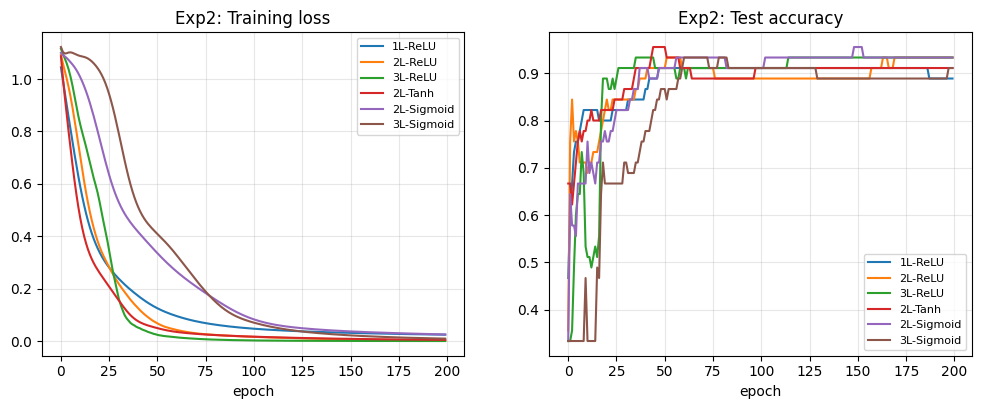

  [saved] ./outputs/exp2_confusion_best.png


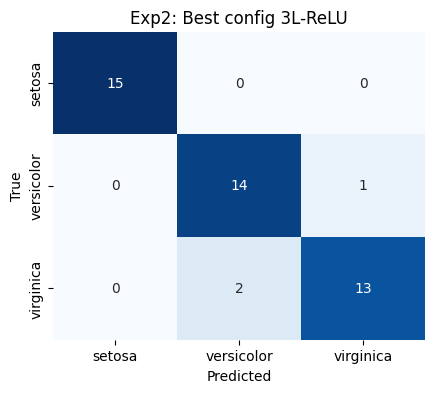


  Observations/Inference: best config = 3L-ReLU (acc 93.33%). Lowest = 1L-ReLU (88.89%). Mean accuracy: ReLU 91.9%, Tanh 91.1%, Sigmoid 92.2%. Iris is small and almost linearly separable, so extra depth gives little gain; Sigmoid usually converges more slowly (higher final loss).

[Exp 2] finished in 2.7s

EXPERIMENT 3: SGD with momentum vs Adam on CIFAR-10
Aim            : Compare convergence speed of two optimizers using the same CNN and identical initial weights.
Dataset        : CIFAR-10 (8000 train / 2000 test subset)
Model          : SmallCNN (3 conv + 2 FC)
Hyperparameters: epochs=3, batch=256, SGD(lr=0.02, momentum=0.9), Adam(lr=1e-3)


100%|██████████| 170M/170M [51:45<00:00, 54.9kB/s]


  [SGD+Momentum] epoch 01/3 | train loss 2.2767 acc 13.09% | eval loss 2.1907 acc 18.05% | 21.9s
  [SGD+Momentum] epoch 02/3 | train loss 2.0236 acc 25.89% | eval loss 1.9298 acc 32.10% | 20.8s
  [SGD+Momentum] epoch 03/3 | train loss 1.7887 acc 34.52% | eval loss 1.6918 acc 38.00% | 20.8s
  [Adam] epoch 01/3 | train loss 1.9952 acc 26.39% | eval loss 1.7646 acc 35.15% | 23.4s
  [Adam] epoch 02/3 | train loss 1.6176 acc 41.00% | eval loss 1.5930 acc 41.40% | 23.4s
  [Adam] epoch 03/3 | train loss 1.4317 acc 47.65% | eval loss 1.4301 acc 48.75% | 21.7s
  [saved] ./outputs/exp3_sgd_vs_adam.png


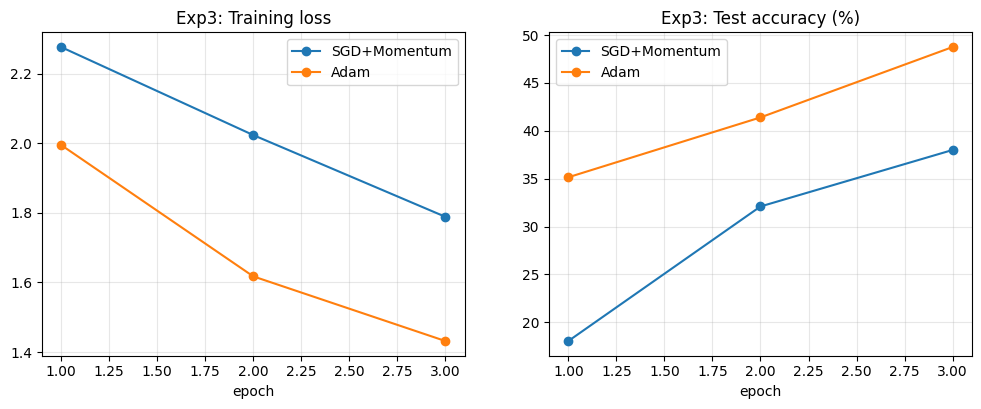


   Optimizer  Final train loss  Final test acc (%)  Best test acc (%)  Epochs to 34% acc  Train time (s)
SGD+Momentum            1.7887               38.00              38.00                  3            63.4
        Adam            1.4317               48.75              48.75                  1            68.5

  Observations/Inference: Adam reached 34% in 1 epoch(s) vs 3 for SGD+Momentum (Adam faster by 2 epochs). Final accuracy: Adam 48.75% vs SGD+Momentum 38.00%. Epoch-1 training loss: Adam 1.995 vs SGD 2.277. Conclusion: adaptive per-parameter learning rates normally give faster early convergence; SGD+momentum often catches up or generalizes better with longer training and tuning.

[Exp 3] finished in 3242.7s

EXPERIMENT 4: CNN from scratch on CIFAR-10
Aim            : Train a 3-block Conv-BN-ReLU-Pool CNN; visualize learned filters and feature maps.
Dataset        : CIFAR-10 (8000 train / 2000 test subset)
Model          : CIFARCNN (3 conv blocks + FC head with dropout)
Hyperp

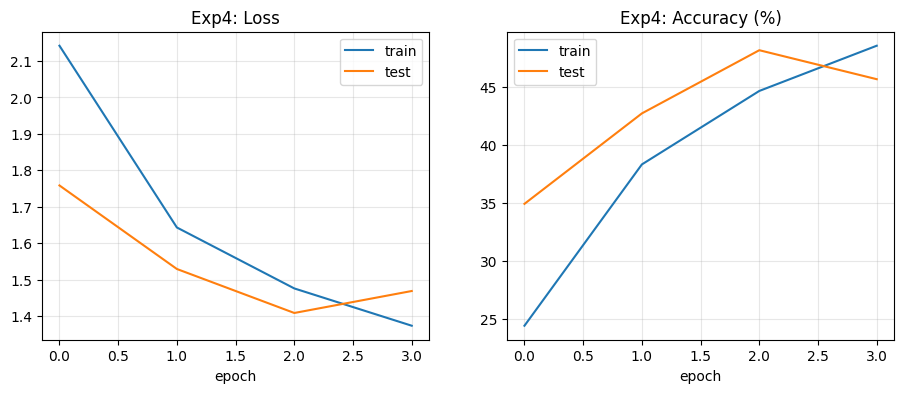

  [saved] ./outputs/exp4_confusion.png


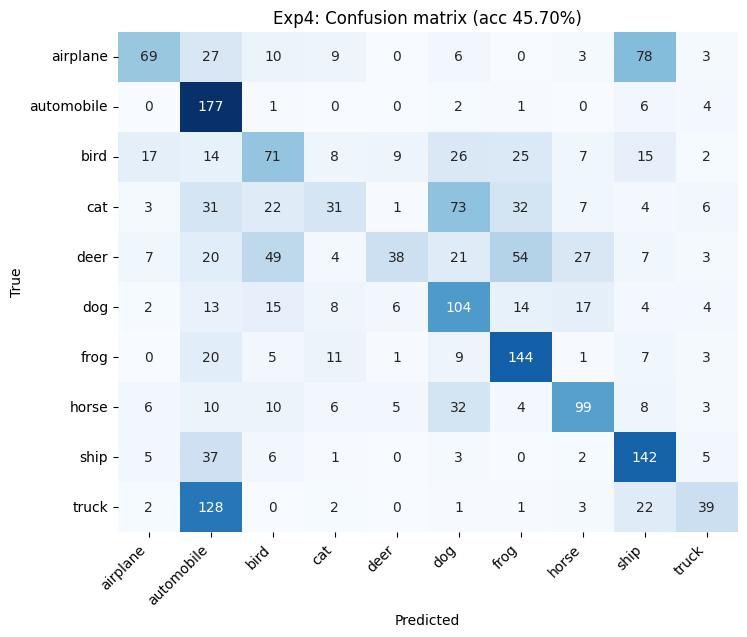

  [saved] ./outputs/exp4_first_layer_filters.png


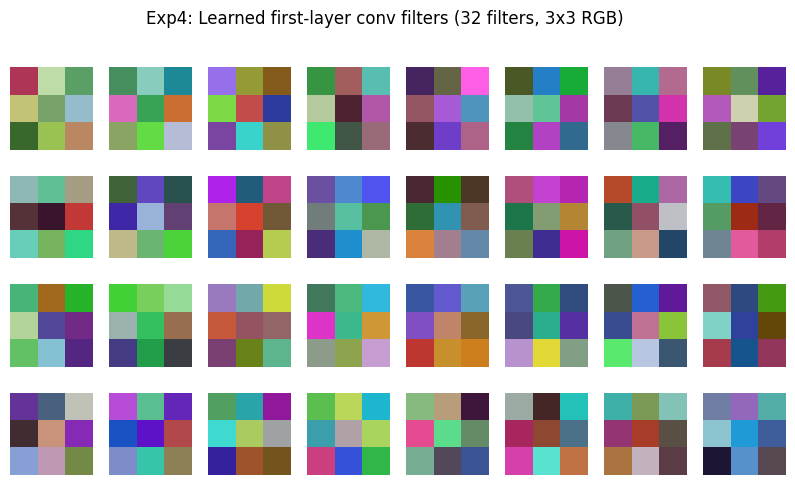

  [saved] ./outputs/exp4_feature_maps.png


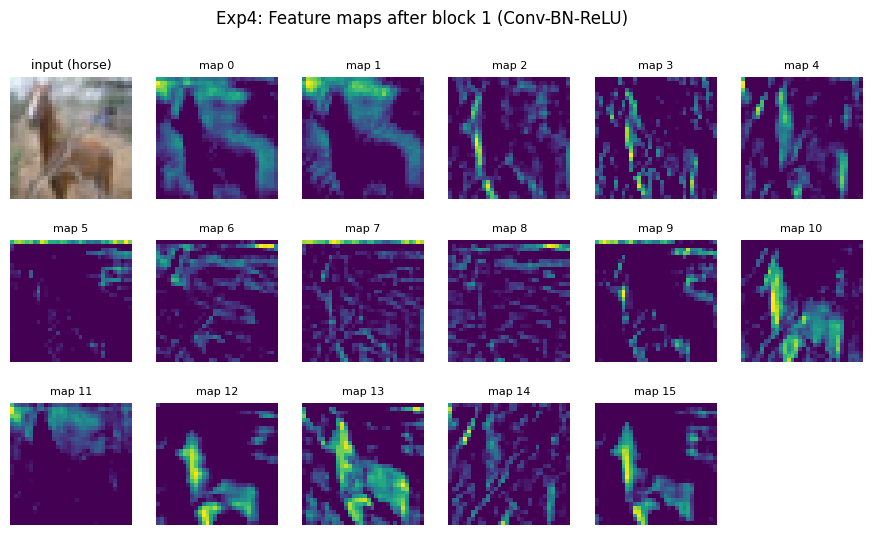


  Observations/Inference: test accuracy 45.70% (macro-F1 0.430) after 4 epochs. Most frequent error: 'truck' misclassified as 'automobile' (128 times). Train/test accuracy gap 2.9 pts. First-layer filters look like oriented edge and colour-opponent detectors; feature maps show early layers keep spatial structure and respond to edges/contrast.

[Exp 4] finished in 123.4s


  [WARN] TFDS cats_vs_dogs unavailable (ModuleNotFoundError: No module named 'importlib_resources'). Falling back to CIFAR-10 cat/dog.

EXPERIMENT 5: VGG vs ResNet vs GoogLeNet (compact versions, trained from scratch)
Aim            : Compare three classic CNN design ideas on binary Dogs-vs-Cats classification.
Dataset        : Cat vs Dog from CIFAR-10 fallback (10000 train/2000 test, 32x32)
Model          : MiniVGG (stacked 3x3), MiniResNet (residual blocks), MiniGoogLeNet (Inception modules)
Hyperparameters: epochs=2, batch=128, Adam lr=2e-3

  >> VGG: 583,394 parameters
  [VGG] epoch 01/2 | train loss 0.6798 acc 60.00% | eval loss 0.6048 acc 67.20% | 80.3s
  [VGG] epoch 02/2 | train loss 0.5612 acc 70.38% | eval loss 0.5425 acc 72.35% | 79.7s

  >> ResNet: 1,226,914 parameters
  [ResNet] epoch 01/2 | train loss 0.6833 acc 58.79% | eval loss 0.6316 acc 64.30% | 121.8s
  [ResNet] epoch 02/2 | train loss 0.6228 acc 65.08% | eval loss 0.6641 acc 61.75% | 122.2s

  >> GoogLeNet: 236,970 

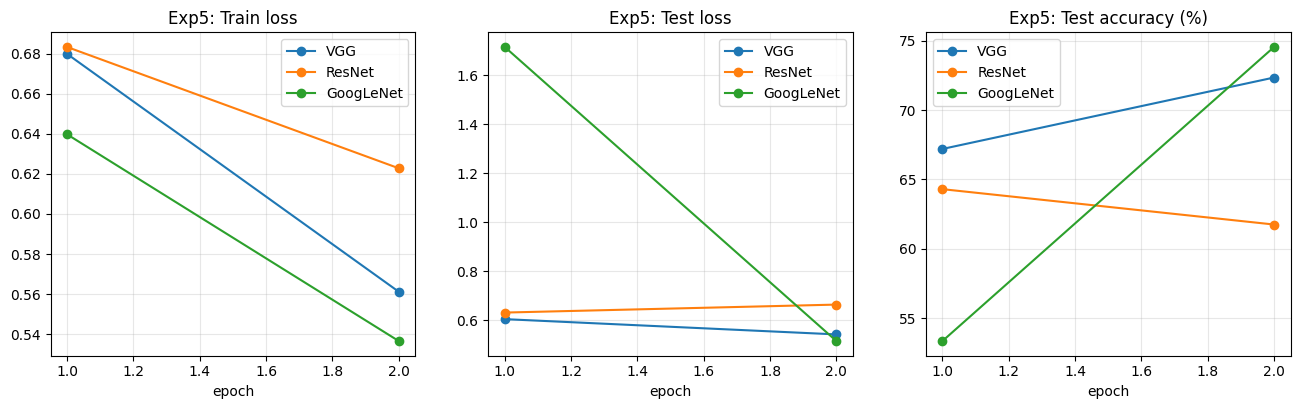

  [saved] ./outputs/exp5_comparison_bars.png


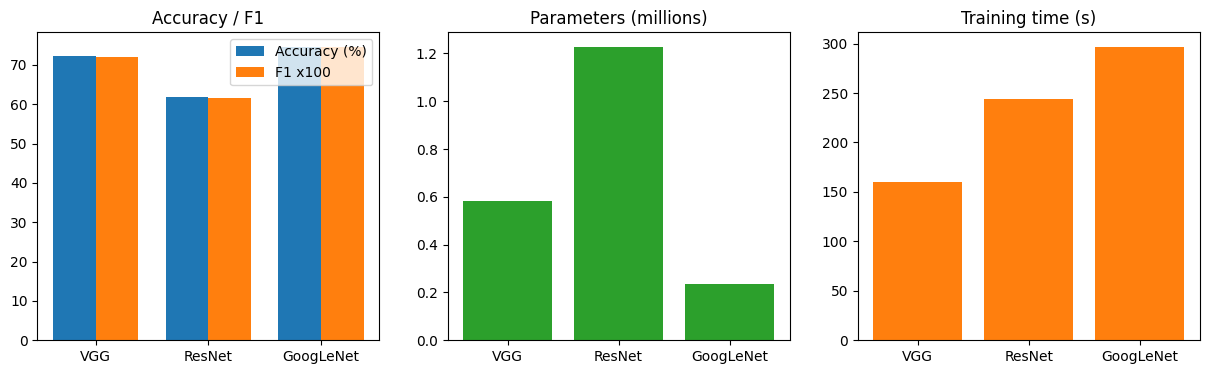


  Observations/Inference: best accuracy = GoogLeNet (74.55%). Smallest model: GoogLeNet; fastest: VGG. Residual shortcuts and Inception branches typically ease optimisation at similar parameter budgets, while the VGG-style plain stack is simplest but least parameter-efficient.

[Exp 5] finished in 739.9s

EXPERIMENT 6: Bidirectional LSTM vs feed-forward NN for time-series forecasting
Aim            : Predict next-month airline passengers from the previous 12 months.
Dataset        : Airline Passengers (144 monthly values, source: URL (jbrownlee/Datasets)), min-max scaled, window=12, 80/20 chronological split
Model          : BiLSTM (hidden 32, 1 layer) vs FFNN (12-32-16-1)
Hyperparameters: epochs=150, batch=16, Adam lr=0.005, MSE loss (CPU)
  [BiLSTM] epoch 001/150 | train MSE 0.10059 | test MSE 0.10042
  [BiLSTM] epoch 030/150 | train MSE 0.00173 | test MSE 0.00687
  [BiLSTM] epoch 060/150 | train MSE 0.00139 | test MSE 0.00371
  [BiLSTM] epoch 090/150 | train MSE 0.00093 | test MSE 

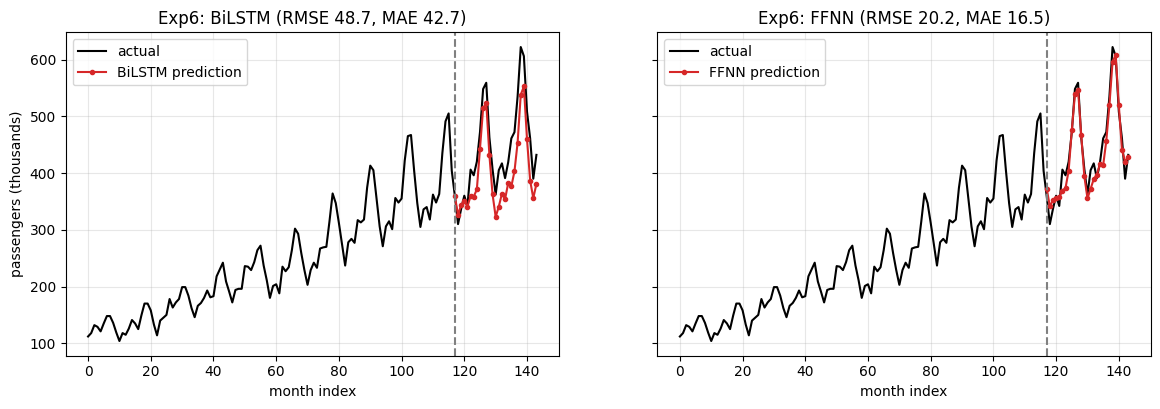

  [saved] ./outputs/exp6_loss_curves.png


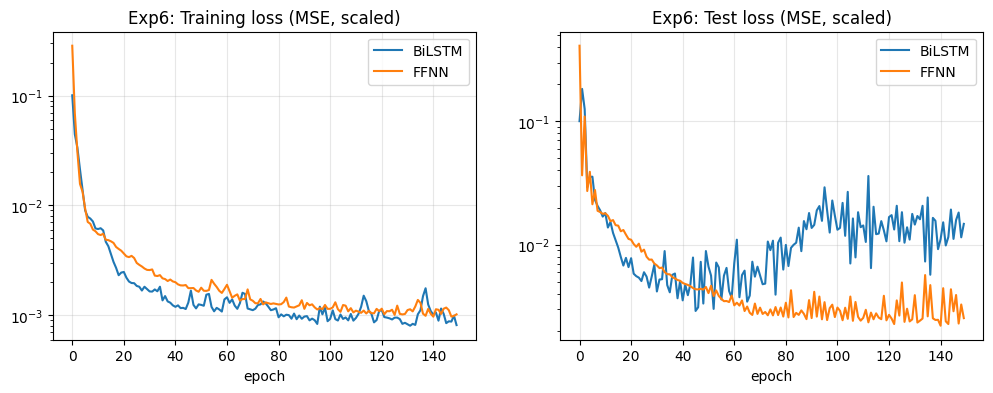


  Observations/Inference: FFNN achieved lower test RMSE (20.17 vs 48.67, 58.6% better). The bidirectional recurrent model reads the window as an ordered sequence, whereas the FFNN treats it as an unordered feature vector. With only 105 training windows both models can overfit or under-extrapolate the upward trend in the test period.

[Exp 6] finished in 8.2s

EXPERIMENT 7: CNN + RNN image captioning (mini synthetic captioning dataset)
Aim            : Generate template captions for images with a CNN encoder and an LSTM decoder (teacher forcing).
Dataset        : MINI synthetic captions on CIFAR-10 images (8000 train / 1000 test). MS COCO is too large, so captions are templated: 'this is a <bright|dark> photo of a <class>'
Model          : Small CNN encoder + Embedding(128) + LSTM(256) decoder, word-level vocab with <start>/<end>
Hyperparameters: epochs=4, batch=256, Adam lr=2e-3, greedy decoding
  Vocabulary size: 21 | caption length (with tokens): 10 | example: this is a dark photo o

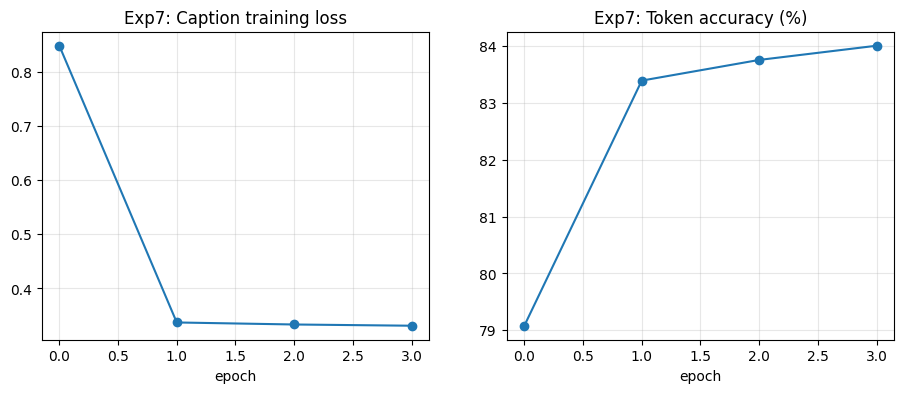

  [saved] ./outputs/exp7_samples.png


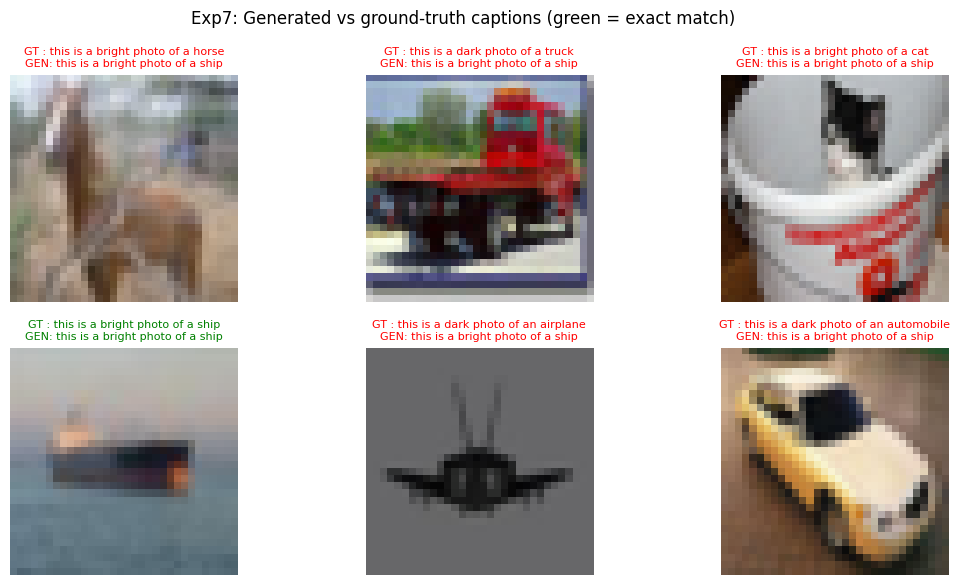


  Observations/Inference: the decoder learned the caption template perfectly in grammar (BLEU-4 0.599) while the semantic content depends on the encoder: class-word accuracy 10.9% (similar to a CIFAR-10 CNN) and brightness-word accuracy 49.9% (an easy low-level cue). This is a toy proxy for COCO captioning, not a replacement.

[Exp 7] finished in 112.5s


100%|██████████| 26.4M/26.4M [00:01<00:00, 17.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 305kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.61MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 9.61MB/s]



EXPERIMENT 8: Variational Autoencoder (VAE)
Aim            : Learn a latent generative model; reconstruct, sample from N(0,I) and interpolate in latent space.
Dataset        : Fashion-MNIST (8000 train imgs, 28x28). NOTE: CelebA is too large for this lab, so Fashion-MNIST is used instead.
Model          : Conv encoder -> (mu, logvar) -> reparameterization -> conv decoder, latent_dim=16
Hyperparameters: epochs=4, batch=256, Adam lr=1e-3, loss = BCE(recon, sum) + KL
  [VAE] epoch 01/4 | total 472.12 | recon 464.16 | KL 7.95
  [VAE] epoch 02/4 | total 364.18 | recon 349.28 | KL 14.90
  [VAE] epoch 03/4 | total 315.49 | recon 300.44 | KL 15.04
  [VAE] epoch 04/4 | total 283.38 | recon 266.53 | KL 16.85
  [saved] ./outputs/exp8_loss_curves.png


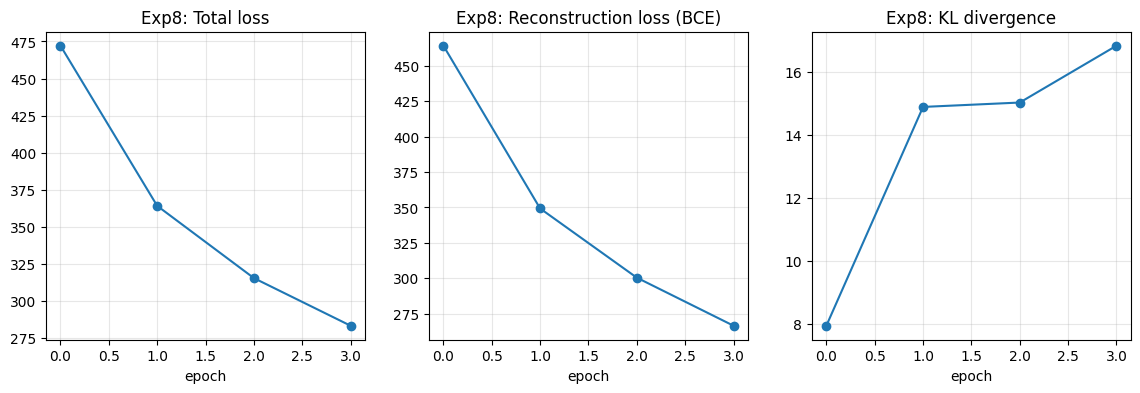

  [saved] ./outputs/exp8_reconstruction.png


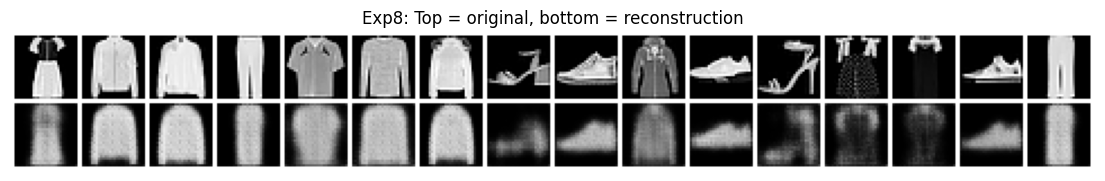

  [saved] ./outputs/exp8_generated.png


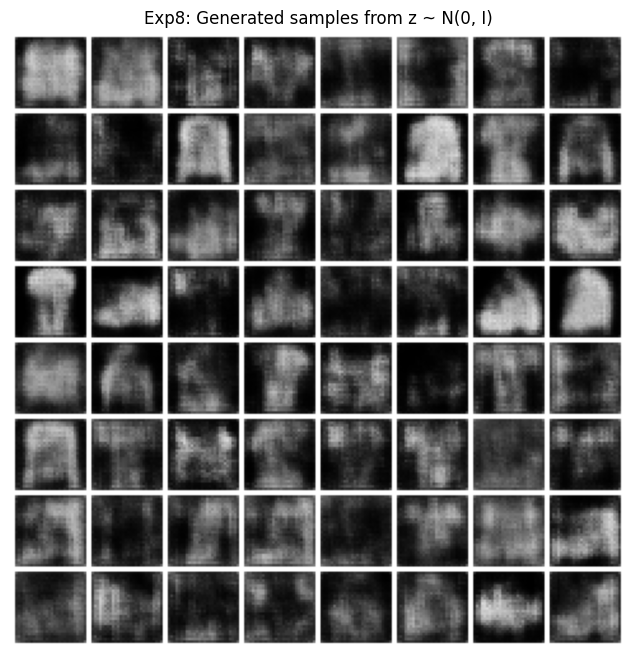

  [saved] ./outputs/exp8_interpolation.png


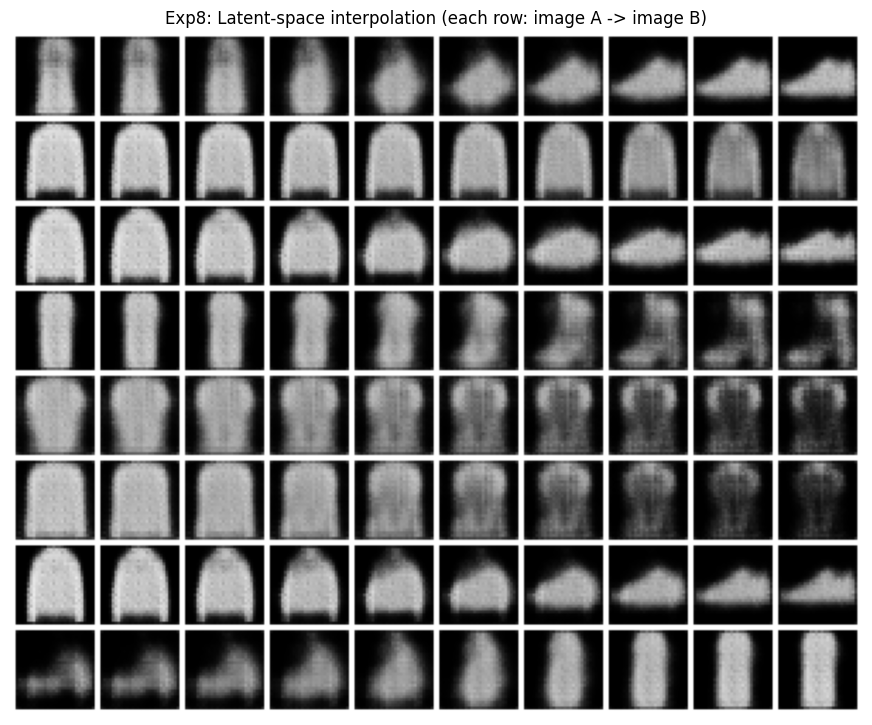

  [VAE-2D] epoch 01/2 | total 451.09 | recon 445.98 | KL 5.11
  [VAE-2D] epoch 02/2 | total 369.24 | recon 361.15 | KL 8.08
  [saved] ./outputs/exp8_latent2d.png


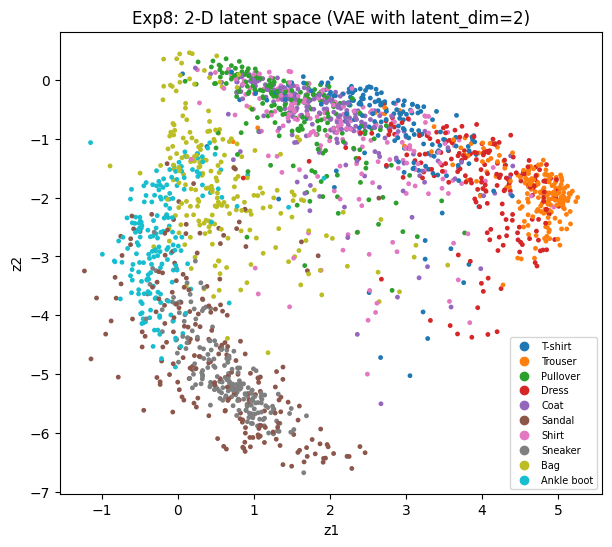


  Observations/Inference: total loss went from 472.1 to 283.4 (recon 266.5 + KL 16.8). Reconstructions keep global shape but are slightly blurry (a known VAE trait from the Gaussian/BCE objective), samples from N(0,I) look plausible because the KL term pulls the posterior towards the prior, and smooth interpolations show a continuous latent space.

[Exp 8] finished in 48.7s

EXPERIMENT 9: Character-level LSTM text generation
Aim            : Train a 2-layer char-LSTM and generate Shakespeare-style text at different temperatures.
Dataset        : Tiny Shakespeare (karpathy/char-rnn), 300,000 characters used
Model          : Embedding(64) + 2-layer LSTM(128) + Linear
Hyperparameters: epochs=4, seq_len=100, batch=128, stride=100, Adam lr=2e-3, grad-clip=1.0
  vocab=62 | train sequences=2849 | val sequences=149
  epoch 01/4 | train loss 3.5323 ppl 34.20 | val loss 3.3620 ppl 28.85 | 15.6s
  epoch 02/4 | train loss 3.1142 ppl 22.52 | val loss 2.9390 ppl 18.90 | 14.7s
  epoch 03/4 | train l

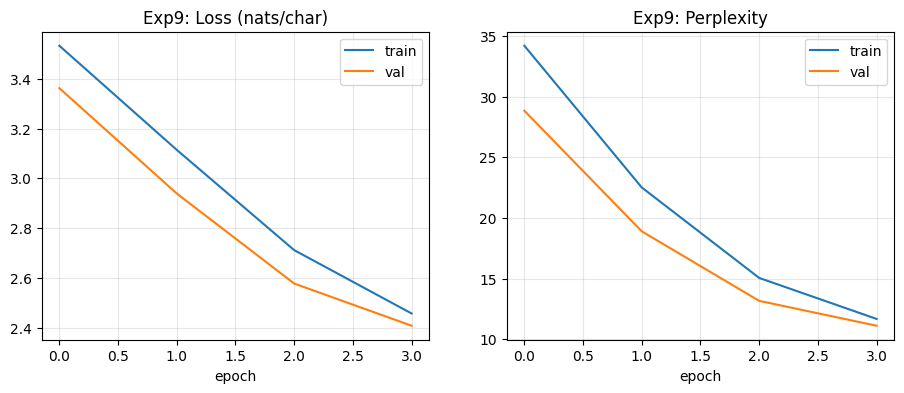


  ---- Generated text (temperature 0.5) ----
ROMEO:

CIOAI:
Mur the so the the sher an the be pat the wend to he you gour he you wour sour,
I be the ther wave soud he me bore ther ame wou arger eres argere be fount in thar the to the the or the wom to the bat and berere are bere the wou the ar the thout the he pace thand the and hy wo thet seell min thar gour the pound herary hire at werand ond you the wee and yo to thar fires wele mod on wene the 


  ---- Generated text (temperature 0.8) ----
ROMEO:

CIOA
:E
ETho the found arss fesae the bajpen ond wey peos, ar meree mer yhand, i sof lithy piten mirt:
Wat math ated bore vher amat an arguk eres.
Whe gall fin
thiis ware thee:

CIRCID:I
Mriln he to hut, auss well;
Whas hane he the sith be ame lard!

GAIRLEUO
GEANS
Snd cour ifs,
Bou or thid by min:
Bareges tithp tenom
Taaty birinlt werare ond yace my o ererd Cint shand fires culemerd,on whner the


  ---- Generated text (temperature 1.0) ----
ROMEO:

CIOA
:E
ETho the found:
Mis fesae th

In [ ]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
AI23531 Deep Learning - Complete Lab Record
10 experiments + 1 mini project, in ONE file (PyTorch).

Run in Colab:  "Run all"  or  !python ai23531_lab.py
Run a subset:  run_all(only=[3, 4, 11])      (11 = mini project)
Scale up/down: edit the CONFIG dict below (QUICK_MODE, EPOCHS, SUBSET_SIZE, BATCH_SIZE).
"""
# ---------------------------------------------------------------------------
# Optional installs. Everything used here is preinstalled on Colab.
# Uncomment only if a package is missing in your environment:
# !pip install -q tensorflow-datasets nltk
# ---------------------------------------------------------------------------

import os, sys, time, math, random, re, copy, io, warnings, urllib.request, traceback
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, RandomSampler, SequentialSampler, BatchSampler
import torchvision
from torchvision import datasets
from torchvision.utils import make_grid

from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_iris, load_digits

warnings.filterwarnings("ignore")

# ===========================================================================
# GLOBAL CONFIG
# ===========================================================================
CONFIG = {
    "QUICK_MODE": True,      # True: ~20 min on a T4. False: 3x epochs, full CIFAR-10 (much slower)
    "EPOCHS": 5,             # base epochs for CNN-type experiments (individual experiments scale it)
    "SUBSET_SIZE": 20000,    # CIFAR-10 training subset size in QUICK_MODE
    "BATCH_SIZE": 256,
    "NUM_WORKERS": 2,
    "SEED": 42,
    "TRY_TFDS": True,        # Exp 5: try tensorflow_datasets cats_vs_dogs first (set False to skip the download)
    "OUT_DIR": "./outputs",
    "DATA_DIR": "./data",
}

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
RESULTS = []          # rows for the final summary table
_CACHE = {}           # dataset cache (each dataset is loaded once and reused)

CIFAR_CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
FMNIST_CLASSES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)


# ===========================================================================
# GENERIC UTILITIES
# ===========================================================================
def set_seed(seed=None):
    seed = CONFIG["SEED"] if seed is None else seed
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def N_TRAIN():
    n = CONFIG["SUBSET_SIZE"] if CONFIG["QUICK_MODE"] else 50000
    return n if USE_AMP else min(n, 8000)


def N_TEST():
    n = max(2000, CONFIG["SUBSET_SIZE"] // 5) if CONFIG["QUICK_MODE"] else 10000
    return n if USE_AMP else min(n, 2000)


def EP(mult=1.0):
    """Epoch budget derived from CONFIG['EPOCHS'] (halved on CPU)."""
    e = CONFIG["EPOCHS"] * mult * (1.0 if CONFIG["QUICK_MODE"] else 3.0)
    if not USE_AMP:
        e *= 0.5
    return max(1 if USE_AMP else 2, int(round(e)))


def amp_ctx():
    return torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP)


def make_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except Exception:
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)


def count_params(m):
    return sum(p.numel() for p in m.parameters())


def banner(title, aim, dataset, model, hparams):
    line = "=" * 80
    print(f"\n{line}\n{title}\n{line}")
    print(f"Aim            : {aim}")
    print(f"Dataset        : {dataset}")
    print(f"Model          : {model}")
    print(f"Hyperparameters: {hparams}")
    print(line)


def save_show(fig, name):
    os.makedirs(CONFIG["OUT_DIR"], exist_ok=True)
    path = os.path.join(CONFIG["OUT_DIR"], name if name.endswith(".png") else name + ".png")
    fig.savefig(path, dpi=110, bbox_inches="tight")
    print(f"  [saved] {path}")
    try:
        plt.show()
    except Exception:
        pass
    plt.close(fig)


def fetch_url(url, timeout=20):
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        return r.read()


def plot_confusion(cm, labels, title, ax=None, cmap="Blues"):
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap=cmap, xticklabels=labels, yticklabels=labels, ax=ax, cbar=False)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title)


def top_confusion(cm, labels):
    c = cm.copy().astype(float)
    np.fill_diagonal(c, 0)
    i, j = np.unravel_index(np.argmax(c), c.shape)
    return f"'{labels[i]}' misclassified as '{labels[j]}' ({int(c[i, j])} times)"


def make_loader(X, y, batch_size=None, shuffle=False, drop_last=False):
    """Fast loader: dataset is indexed with whole batches of indices (no per-sample collate)."""
    bs = batch_size or CONFIG["BATCH_SIZE"]
    ds = TensorDataset(X, y)
    sampler = RandomSampler(ds) if shuffle else SequentialSampler(ds)
    bsamp = BatchSampler(sampler, bs, drop_last)
    nw = CONFIG["NUM_WORKERS"]
    return DataLoader(ds, batch_size=None, sampler=bsamp, num_workers=nw,
                      pin_memory=USE_AMP, persistent_workers=nw > 0)


def evaluate(model, loader):
    model.eval()
    tot, correct, n = 0.0, 0, 0
    P, Y = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(DEVICE, non_blocking=True); yb = yb.to(DEVICE, non_blocking=True)
            with amp_ctx():
                out = model(xb)
            out = out.float()
            tot += F.cross_entropy(out, yb, reduction="sum").item()
            pred = out.argmax(1)
            correct += (pred == yb).sum().item(); n += len(yb)
            P.append(pred.cpu()); Y.append(yb.cpu())
    return dict(loss=tot / n, acc=correct / n, preds=torch.cat(P).numpy(), labels=torch.cat(Y).numpy())


def train_model(model, train_loader, eval_loader, optimizer, epochs, scheduler=None,
                augment=None, label="model", grad_clip=None, log=True):
    """Generic supervised training loop (AMP on GPU). Returns history dict."""
    model.to(DEVICE)
    scaler = make_scaler()
    hist = dict(train_loss=[], train_acc=[], test_loss=[], test_acc=[], epoch_time=[])
    t_start = time.time()
    for ep in range(1, epochs + 1):
        model.train()
        t0 = time.time()
        tl = torch.zeros((), device=DEVICE); tc = torch.zeros((), device=DEVICE); n = 0
        for xb, yb in train_loader:
            xb = xb.to(DEVICE, non_blocking=True); yb = yb.to(DEVICE, non_blocking=True)
            if augment is not None:
                xb = augment(xb)
            optimizer.zero_grad(set_to_none=True)
            with amp_ctx():
                out = model(xb)
            loss = F.cross_entropy(out.float(), yb)
            scaler.scale(loss).backward()
            if grad_clip:
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            scaler.step(optimizer); scaler.update()
            if scheduler is not None:
                scheduler.step()
            tl += loss.detach() * len(yb); tc += (out.argmax(1) == yb).sum(); n += len(yb)
        ev = evaluate(model, eval_loader)
        hist["train_loss"].append(tl.item() / n); hist["train_acc"].append(tc.item() / n)
        hist["test_loss"].append(ev["loss"]); hist["test_acc"].append(ev["acc"])
        hist["epoch_time"].append(time.time() - t0)
        if log:
            print(f"  [{label}] epoch {ep:02d}/{epochs} | train loss {hist['train_loss'][-1]:.4f} acc {hist['train_acc'][-1]*100:5.2f}% "
                  f"| eval loss {ev['loss']:.4f} acc {ev['acc']*100:5.2f}% | {hist['epoch_time'][-1]:.1f}s")
    hist["train_time"] = time.time() - t_start
    return hist


def augment_batch(x, pad=4):
    """GPU random horizontal flip + random crop (reflect padding) for a normalized batch."""
    n, c, h, w = x.shape
    dev = x.device
    flip = torch.rand(n, device=dev) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    xp = F.pad(x, (pad, pad, pad, pad), mode="reflect")
    i = torch.randint(0, 2 * pad + 1, (n,), device=dev)
    j = torch.randint(0, 2 * pad + 1, (n,), device=dev)
    rows = i[:, None] + torch.arange(h, device=dev)[None]
    cols = j[:, None] + torch.arange(w, device=dev)[None]
    bi = torch.arange(n, device=dev)[:, None, None, None]
    ci = torch.arange(c, device=dev)[None, :, None, None]
    return xp[bi, ci, rows[:, None, :, None], cols[:, None, None, :]]


# ===========================================================================
# DATASETS (loaded once, cached, with offline fallbacks)
# ===========================================================================
def get_gray_arrays(name="MNIST"):
    """MNIST / FashionMNIST uint8 arrays. Fallback: sklearn digits upsampled to 28x28."""
    if name in _CACHE:
        return _CACHE[name]
    try:
        cls = datasets.MNIST if name == "MNIST" else datasets.FashionMNIST
        tr = cls(CONFIG["DATA_DIR"], train=True, download=True)
        te = cls(CONFIG["DATA_DIR"], train=False, download=True)
        d = dict(Xtr=tr.data.numpy(), ytr=tr.targets.numpy(), Xte=te.data.numpy(), yte=te.targets.numpy(),
                 real=True, classes=[str(i) for i in range(10)] if name == "MNIST" else FMNIST_CLASSES)
    except Exception as e:
        print(f"  [WARN] could not download {name} ({type(e).__name__}); using sklearn digits fallback.")
        dg = load_digits()
        X = torch.tensor(dg.images / 16.0, dtype=torch.float32)[:, None]
        X = F.interpolate(X, size=28, mode="bilinear", align_corners=False)
        X = (X.squeeze(1).numpy() * 255).astype(np.uint8)
        Xtr, Xte, ytr, yte = train_test_split(X, dg.target, test_size=0.25, random_state=0, stratify=dg.target)
        d = dict(Xtr=Xtr, ytr=ytr, Xte=Xte, yte=yte, real=False, classes=[str(i) for i in range(10)])
    _CACHE[name] = d
    return d


def get_gray_subset(name, ntr, nte):
    d = get_gray_arrays(name)
    rs = np.random.RandomState(0)
    itr = rs.permutation(len(d["Xtr"]))[:ntr]
    ite = rs.permutation(len(d["Xte"]))[:nte]
    return d["Xtr"][itr], d["ytr"][itr], d["Xte"][ite], d["yte"][ite], d


def synthetic_cifar(n_tr=10000, n_te=2000, seed=0):
    """Offline fallback: class-conditional colour/texture images (32x32x3)."""
    rng = np.random.RandomState(seed)
    yy, xx = np.meshgrid(np.linspace(0, 1, 32), np.linspace(0, 1, 32), indexing="ij")

    def make(n):
        y = rng.randint(0, 10, n)
        X = np.zeros((n, 32, 32, 3), np.float32)
        for i, c in enumerate(y):
            base = np.array([(c * 37 % 255) / 255, (c * 91 % 255) / 255, (c * 53 % 255) / 255])
            pat = 0.5 + 0.5 * np.sin(2 * np.pi * (2 + c) * (xx * np.cos(c) + yy * np.sin(c)) + rng.rand() * 2 * np.pi)
            img = base[None, None, :] * 0.6 + 0.4 * pat[..., None] * (0.5 + 0.5 * base[None, None, ::-1]) \
                  + rng.randn(32, 32, 3) * 0.1
            X[i] = np.clip(img, 0, 1)
        return (X * 255).astype(np.uint8), y

    Xtr, ytr = make(n_tr); Xte, yte = make(n_te)
    return dict(Xtr=Xtr, ytr=ytr, Xte=Xte, yte=yte, real=False)


def get_cifar_arrays():
    if "CIFAR10" in _CACHE:
        return _CACHE["CIFAR10"]
    try:
        tr = datasets.CIFAR10(CONFIG["DATA_DIR"], train=True, download=True)
        te = datasets.CIFAR10(CONFIG["DATA_DIR"], train=False, download=True)
        d = dict(Xtr=tr.data, ytr=np.array(tr.targets), Xte=te.data, yte=np.array(te.targets), real=True)
    except Exception as e:
        print(f"  [WARN] could not download CIFAR-10 ({type(e).__name__}); using synthetic CIFAR-like fallback.")
        d = synthetic_cifar()
    _CACHE["CIFAR10"] = d
    return d


def to_cifar_tensor(X, normalize=True):
    x = torch.from_numpy(X).permute(0, 3, 1, 2).float() / 255.0
    if normalize:
        m = torch.tensor(CIFAR_MEAN)[None, :, None, None]; s = torch.tensor(CIFAR_STD)[None, :, None, None]
        x = (x - m) / s
    return x.contiguous()


def denorm_cifar(x):
    m = torch.tensor(CIFAR_MEAN, device=x.device)[None, :, None, None]
    s = torch.tensor(CIFAR_STD, device=x.device)[None, :, None, None]
    return (x * s + m).clamp(0, 1)


def get_cifar(n_train=None, n_test=None, normalize=True):
    """Cached CIFAR-10 tensors (float32, NCHW). Subsets are nested (same fixed permutation)."""
    n_train = n_train or N_TRAIN(); n_test = n_test or N_TEST()
    key = ("cifar", n_train, n_test, normalize)
    if key in _CACHE:
        return _CACHE[key]
    d = get_cifar_arrays()
    itr = np.random.RandomState(0).permutation(len(d["Xtr"]))[:n_train]
    ite = np.random.RandomState(1).permutation(len(d["Xte"]))[:n_test]
    out = (to_cifar_tensor(d["Xtr"][itr], normalize), torch.from_numpy(d["ytr"][itr]).long(),
           to_cifar_tensor(d["Xte"][ite], normalize), torch.from_numpy(d["yte"][ite]).long())
    _CACHE[key] = out
    return out


# ===========================================================================
# SHARED MODELS
# ===========================================================================
class SmallCNN(nn.Module):
    """Plain small CNN (no BN): 3x[conv-relu-pool] + MLP head. Input 3x32x32."""
    def __init__(self, nc=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(128 * 4 * 4, 256), nn.ReLU(), nn.Linear(256, nc))

    def forward(self, x):
        return self.classifier(self.features(x))


def conv_bn_relu(i, o, k=3, s=1, p=1):
    return nn.Sequential(nn.Conv2d(i, o, k, s, p, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))


class CIFARCNN(nn.Module):
    """Exp 4: 3 conv blocks (Conv-BN-ReLU-Pool) + classifier head."""
    def __init__(self, nc=10):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        self.block1, self.block2, self.block3 = block(3, 32), block(32, 64), block(64, 128)
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(128 * 4 * 4, 256), nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, nc))

    def forward(self, x):
        return self.head(self.block3(self.block2(self.block1(x))))


# ===========================================================================
# EXPERIMENT 1 - Three-layer NN from scratch (NumPy)
# ===========================================================================
def _softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


class NumpyMLP:
    """784 -> h1 -> h2 -> 10. Manual forward + backprop, softmax cross-entropy, mini-batch GD."""
    def __init__(self, sizes=(784, 128, 64, 10), activation="relu", seed=0):
        rng = np.random.RandomState(seed)
        self.act = activation
        self.W, self.b = [], []
        for i in range(len(sizes) - 1):
            scale = np.sqrt(2.0 / sizes[i]) if activation == "relu" else np.sqrt(1.0 / sizes[i])
            self.W.append((rng.randn(sizes[i], sizes[i + 1]) * scale).astype(np.float32))
            self.b.append(np.zeros((1, sizes[i + 1]), np.float32))

    def _f(self, z):
        return np.maximum(0, z) if self.act == "relu" else 1.0 / (1.0 + np.exp(-z))

    def _df(self, a, z):
        return (z > 0).astype(np.float32) if self.act == "relu" else a * (1 - a)

    def forward(self, X):
        self.A, self.Z = [X], []
        a = X
        for i in range(len(self.W) - 1):
            z = a @ self.W[i] + self.b[i]
            a = self._f(z)
            self.Z.append(z); self.A.append(a)
        z = a @ self.W[-1] + self.b[-1]
        self.Z.append(z)
        return _softmax(z)

    def backward(self, probs, Y, lr):
        dz = (probs - Y) / probs.shape[0]                 # dL/dlogits for softmax + CE
        for i in reversed(range(len(self.W))):
            dW = self.A[i].T @ dz
            db = dz.sum(axis=0, keepdims=True)
            if i > 0:
                dz_next = (dz @ self.W[i].T) * self._df(self.A[i], self.Z[i - 1])
            self.W[i] -= lr * dW
            self.b[i] -= lr * db
            if i > 0:
                dz = dz_next

    def predict(self, X):
        return self.forward(X).argmax(1)


def exp1():
    epochs, bs, lr = (25 if CONFIG["QUICK_MODE"] else 60), 128, 0.1
    banner("EXPERIMENT 1: Three-layer neural network from scratch (NumPy, no autograd)",
           "Implement forward/backward propagation manually and train with mini-batch gradient descent.",
           "MNIST (10k train / 2k test subset)", "784-128-64-10 MLP, ReLU hidden, softmax + cross-entropy",
           f"epochs={epochs}, batch={bs}, lr={lr}, He init")
    set_seed()
    Xtr_raw, ytr, Xte_raw, yte, d = get_gray_subset("MNIST", 10000, 2000)
    if not d["real"]:
        print("  NOTE: real MNIST unavailable -> using sklearn digits fallback.")
    prep = lambda X: ((X.reshape(len(X), -1).astype(np.float32) / 255.0) - 0.1307) / 0.3081
    Xtr, Xte = prep(Xtr_raw), prep(Xte_raw)
    Ytr = np.eye(10, dtype=np.float32)[ytr]
    net = NumpyMLP()
    H = dict(loss=[], test_loss=[], acc=[], test_acc=[])
    rs = np.random.RandomState(0)
    for ep in range(1, epochs + 1):
        idx = rs.permutation(len(Xtr)); tl, tc = 0.0, 0
        for s in range(0, len(idx), bs):
            b = idx[s:s + bs]
            p = net.forward(Xtr[b])
            tl += -np.log(p[np.arange(len(b)), ytr[b]] + 1e-12).sum()
            tc += (p.argmax(1) == ytr[b]).sum()
            net.backward(p, Ytr[b], lr)
        pt = net.forward(Xte)
        H["loss"].append(tl / len(Xtr)); H["acc"].append(tc / len(Xtr))
        H["test_loss"].append(float(-np.log(pt[np.arange(len(yte)), yte] + 1e-12).mean()))
        H["test_acc"].append(float((pt.argmax(1) == yte).mean()))
        print(f"  epoch {ep:02d}/{epochs} | train loss {H['loss'][-1]:.4f} acc {H['acc'][-1]*100:5.2f}% "
              f"| test loss {H['test_loss'][-1]:.4f} acc {H['test_acc'][-1]*100:5.2f}%")
    preds = net.predict(Xte)
    acc = (preds == yte).mean()
    print(f"\n  FINAL TEST ACCURACY: {acc*100:.2f}%")

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(H["loss"], label="train"); ax[0].plot(H["test_loss"], label="test")
    ax[0].set_title("Exp1: Loss curve"); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(H["acc"], label="train"); ax[1].plot(H["test_acc"], label="test")
    ax[1].set_title("Exp1: Accuracy curve"); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
    save_show(fig, "exp1_curves")

    fig, axes = plt.subplots(2, 5, figsize=(10, 4.6))
    for k, ax in enumerate(axes.ravel()):
        ax.imshow(Xte_raw[k], cmap="gray"); ok = preds[k] == yte[k]
        ax.set_title(f"pred {preds[k]} | true {yte[k]}", color="green" if ok else "red", fontsize=9); ax.axis("off")
    fig.suptitle("Exp1: 10 sample predictions (green = correct, red = wrong)")
    save_show(fig, "exp1_predictions")

    cm = confusion_matrix(yte, preds, labels=range(10))
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    plot_confusion(cm, range(10), f"Exp1: Confusion matrix (acc {acc*100:.2f}%)", ax)
    save_show(fig, "exp1_confusion")

    print(f"\n  Observations/Inference: the loss fell from {H['loss'][0]:.3f} to {H['loss'][-1]:.3f} and test accuracy "
          f"reached {acc*100:.2f}% with only manual gradients, which confirms the backprop equations are correct. "
          f"Train/test accuracy gap = {(H['acc'][-1]-H['test_acc'][-1])*100:.2f} pts. Most frequent error: {top_confusion(cm, list(range(10)))}.")
    return dict(dataset="MNIST (10k/2k)", model="NumPy MLP 784-128-64-10", metric=f"Test acc {acc*100:.2f}%")


# ===========================================================================
# EXPERIMENT 2 - MLP on Iris (layers x activations)
# ===========================================================================
def build_mlp(in_dim, hidden, n_layers, act, out_dim):
    A = {"ReLU": nn.ReLU, "Tanh": nn.Tanh, "Sigmoid": nn.Sigmoid}[act]
    layers, d = [], in_dim
    for _ in range(n_layers):
        layers += [nn.Linear(d, hidden), A()]; d = hidden
    layers.append(nn.Linear(d, out_dim))
    return nn.Sequential(*layers)


def exp2():
    epochs, lr, hidden = 200, 0.01, 16
    banner("EXPERIMENT 2: MLP on Iris - effect of depth and activation function",
           "Compare MLPs with 1/2/3 hidden layers and ReLU/Tanh/Sigmoid activations.",
           "Iris (sklearn load_iris), 70/30 stratified split, standardized",
           f"MLP, {hidden} units/hidden layer, Adam, full-batch",
           f"epochs={epochs}, lr={lr}, 6 configurations")
    iris = load_iris()
    Xtr, Xte, ytr, yte = train_test_split(iris.data, iris.target, test_size=0.3, stratify=iris.target, random_state=42)
    sc = StandardScaler().fit(Xtr)
    Xt = torch.tensor(sc.transform(Xtr), dtype=torch.float32); Xv = torch.tensor(sc.transform(Xte), dtype=torch.float32)
    yt = torch.tensor(ytr).long(); yv = torch.tensor(yte).long()
    configs = [(1, "ReLU"), (2, "ReLU"), (3, "ReLU"), (2, "Tanh"), (2, "Sigmoid"), (3, "Sigmoid")]
    rows, curves, preds_all = [], {}, {}
    for nl, act in configs:
        name = f"{nl}L-{act}"
        set_seed()
        m = build_mlp(4, hidden, nl, act, 3)
        opt = torch.optim.Adam(m.parameters(), lr=lr)
        L, A = [], []
        for ep in range(epochs):
            m.train(); opt.zero_grad()
            loss = F.cross_entropy(m(Xt), yt); loss.backward(); opt.step()
            m.eval()
            with torch.no_grad():
                a = (m(Xv).argmax(1) == yv).float().mean().item()
            L.append(loss.item()); A.append(a)
        with torch.no_grad():
            pv = m(Xv).argmax(1).numpy()
        curves[name] = (L, A); preds_all[name] = pv
        rows.append(dict(Config=name, HiddenLayers=nl, Activation=act, TestAcc=round(A[-1] * 100, 2),
                         FinalLoss=round(L[-1], 4), Params=count_params(m)))
        print(f"  {name:10s} | test acc {A[-1]*100:6.2f}% | final train loss {L[-1]:.4f} | params {count_params(m)}")
    df = pd.DataFrame(rows)
    print("\n" + df.to_string(index=False))
    df.to_csv(os.path.join(CONFIG["OUT_DIR"], "exp2_table.csv"), index=False)

    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    for k, (L, A) in curves.items():
        ax[0].plot(L, label=k); ax[1].plot(A, label=k)
    ax[0].set_title("Exp2: Training loss"); ax[1].set_title("Exp2: Test accuracy")
    for a in ax:
        a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend(fontsize=8)
    save_show(fig, "exp2_curves")

    best = df.sort_values(["TestAcc", "FinalLoss"], ascending=[False, True]).iloc[0]["Config"]
    cm = confusion_matrix(yte, preds_all[best])
    fig, ax = plt.subplots(figsize=(4.8, 4))
    plot_confusion(cm, iris.target_names, f"Exp2: Best config {best}", ax)
    save_show(fig, "exp2_confusion_best")
    worst = df.sort_values("TestAcc").iloc[0]
    print(f"\n  Observations/Inference: best config = {best} (acc {df.set_index('Config').loc[best,'TestAcc']}%). "
          f"Lowest = {worst['Config']} ({worst['TestAcc']}%). Mean accuracy: ReLU {df[df.Activation=='ReLU'].TestAcc.mean():.1f}%, "
          f"Tanh {df[df.Activation=='Tanh'].TestAcc.mean():.1f}%, Sigmoid {df[df.Activation=='Sigmoid'].TestAcc.mean():.1f}%. "
          f"Iris is small and almost linearly separable, so extra depth gives little gain; Sigmoid usually converges more slowly (higher final loss).")
    return dict(dataset="Iris", model="MLP (6 configs)", metric=f"Best {best}: {df.TestAcc.max():.2f}%")


# ===========================================================================
# EXPERIMENT 3 - SGD+momentum vs Adam on CIFAR-10
# ===========================================================================
def epochs_to_target(accs, target):
    for i, a in enumerate(accs):
        if a >= target:
            return i + 1
    return None


def exp3():
    epochs = EP(1.2)
    banner("EXPERIMENT 3: SGD with momentum vs Adam on CIFAR-10",
           "Compare convergence speed of two optimizers using the same CNN and identical initial weights.",
           f"CIFAR-10 ({N_TRAIN()} train / {N_TEST()} test subset)", "SmallCNN (3 conv + 2 FC)",
           f"epochs={epochs}, batch={CONFIG['BATCH_SIZE']}, SGD(lr=0.02, momentum=0.9), Adam(lr=1e-3)")
    Xtr, ytr, Xte, yte = get_cifar()
    trl, tel = make_loader(Xtr, ytr, shuffle=True), make_loader(Xte, yte)
    set_seed()
    base = SmallCNN(); init_state = copy.deepcopy(base.state_dict())
    H, times = {}, {}
    for name, mk in [("SGD+Momentum", lambda p: torch.optim.SGD(p, lr=0.02, momentum=0.9)),
                     ("Adam", lambda p: torch.optim.Adam(p, lr=1e-3))]:
        set_seed()
        m = SmallCNN(); m.load_state_dict(init_state)
        H[name] = train_model(m, trl, tel, mk(m.parameters()), epochs, label=name)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    for k, h in H.items():
        ax[0].plot(range(1, epochs + 1), h["train_loss"], marker="o", label=k)
        ax[1].plot(range(1, epochs + 1), np.array(h["test_acc"]) * 100, marker="o", label=k)
    ax[0].set_title("Exp3: Training loss"); ax[1].set_title("Exp3: Test accuracy (%)")
    for a in ax:
        a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend()
    save_show(fig, "exp3_sgd_vs_adam")

    best_each = [max(h["test_acc"]) for h in H.values()]
    target = 0.5
    if min(best_each) < target:
        target = round(0.9 * min(best_each), 3)
    rows = []
    for k, h in H.items():
        e = epochs_to_target(h["test_acc"], target)
        rows.append({"Optimizer": k, "Final train loss": round(h["train_loss"][-1], 4),
                     "Final test acc (%)": round(h["test_acc"][-1] * 100, 2),
                     "Best test acc (%)": round(max(h["test_acc"]) * 100, 2),
                     f"Epochs to {target*100:.0f}% acc": e if e else "not reached",
                     "Train time (s)": round(h["train_time"], 1)})
    df = pd.DataFrame(rows)
    print("\n" + df.to_string(index=False))
    ea, es = epochs_to_target(H["Adam"]["test_acc"], target), epochs_to_target(H["SGD+Momentum"]["test_acc"], target)
    fa, fs = H["Adam"]["test_acc"][-1] * 100, H["SGD+Momentum"]["test_acc"][-1] * 100
    if ea and es:
        speed = (f"Adam reached {target*100:.0f}% in {ea} epoch(s) vs {es} for SGD+Momentum "
                 f"({'Adam faster by ' + str(es-ea) if es > ea else 'SGD+Momentum faster by ' + str(ea-es) if ea > es else 'tie'} epochs)")
    else:
        speed = "at least one optimizer did not reach the target accuracy"
    print(f"\n  Observations/Inference: {speed}. Final accuracy: Adam {fa:.2f}% vs SGD+Momentum {fs:.2f}%. "
          f"Epoch-1 training loss: Adam {H['Adam']['train_loss'][0]:.3f} vs SGD {H['SGD+Momentum']['train_loss'][0]:.3f}. "
          f"Conclusion: adaptive per-parameter learning rates normally give faster early convergence; SGD+momentum often "
          f"catches up or generalizes better with longer training and tuning.")
    return dict(dataset="CIFAR-10 subset", model="SmallCNN", metric=f"Adam {fa:.1f}% vs SGD+M {fs:.1f}%")


# ===========================================================================
# EXPERIMENT 4 - CNN from scratch on CIFAR-10 (+ filters / feature maps)
# ===========================================================================
def exp4():
    epochs = EP(1.6)
    banner("EXPERIMENT 4: CNN from scratch on CIFAR-10",
           "Train a 3-block Conv-BN-ReLU-Pool CNN; visualize learned filters and feature maps.",
           f"CIFAR-10 ({N_TRAIN()} train / {N_TEST()} test subset)", "CIFARCNN (3 conv blocks + FC head with dropout)",
           f"epochs={epochs}, batch={CONFIG['BATCH_SIZE']}, Adam lr=2e-3")
    Xtr, ytr, Xte, yte = get_cifar()
    trl, tel = make_loader(Xtr, ytr, shuffle=True), make_loader(Xte, yte)
    set_seed()
    model = CIFARCNN()
    print(f"  Parameters: {count_params(model):,}")
    h = train_model(model, trl, tel, torch.optim.Adam(model.parameters(), lr=2e-3), epochs, label="CNN")
    ev = evaluate(model, tel)
    print(f"\n  FINAL TEST ACCURACY: {ev['acc']*100:.2f}%\n")
    print(classification_report(ev["labels"], ev["preds"], target_names=CIFAR_CLASSES, digits=3))

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(h["train_loss"], label="train"); ax[0].plot(h["test_loss"], label="test"); ax[0].set_title("Exp4: Loss")
    ax[1].plot(np.array(h["train_acc"]) * 100, label="train"); ax[1].plot(np.array(h["test_acc"]) * 100, label="test")
    ax[1].set_title("Exp4: Accuracy (%)")
    for a in ax:
        a.set_xlabel("epoch"); a.legend(); a.grid(alpha=.3)
    save_show(fig, "exp4_curves")

    cm = confusion_matrix(ev["labels"], ev["preds"])
    fig, ax = plt.subplots(figsize=(8, 6.5))
    plot_confusion(cm, CIFAR_CLASSES, f"Exp4: Confusion matrix (acc {ev['acc']*100:.2f}%)", ax)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    save_show(fig, "exp4_confusion")

    w = model.block1[0].weight.detach().cpu()
    wn = (w - w.min()) / (w.max() - w.min() + 1e-8)
    fig, axes = plt.subplots(4, 8, figsize=(10, 5.4))
    for i, ax in enumerate(axes.ravel()):
        ax.imshow(wn[i].permute(1, 2, 0).numpy(), interpolation="nearest"); ax.axis("off")
    fig.suptitle("Exp4: Learned first-layer conv filters (32 filters, 3x3 RGB)")
    save_show(fig, "exp4_first_layer_filters")

    model.eval()
    with torch.no_grad():
        x = Xte[0:1].to(DEVICE)
        fm = model.block1[:3](x)[0].cpu()
    fig, axes = plt.subplots(3, 6, figsize=(11, 6))
    axes[0, 0].imshow(denorm_cifar(Xte[0:1])[0].permute(1, 2, 0).numpy())
    axes[0, 0].set_title(f"input ({CIFAR_CLASSES[yte[0]]})", fontsize=9)
    for i, ax in enumerate(axes.ravel()[1:17]):
        ax.imshow(fm[i].numpy(), cmap="viridis"); ax.set_title(f"map {i}", fontsize=8)
    for ax in axes.ravel():
        ax.axis("off")
    fig.suptitle("Exp4: Feature maps after block 1 (Conv-BN-ReLU)")
    save_show(fig, "exp4_feature_maps")

    f1 = f1_score(ev["labels"], ev["preds"], average="macro")
    print(f"\n  Observations/Inference: test accuracy {ev['acc']*100:.2f}% (macro-F1 {f1:.3f}) after {epochs} epochs. "
          f"Most frequent error: {top_confusion(cm, CIFAR_CLASSES)}. Train/test accuracy gap "
          f"{(h['train_acc'][-1]-h['test_acc'][-1])*100:.1f} pts. First-layer filters look like oriented edge and colour-opponent detectors; "
          f"feature maps show early layers keep spatial structure and respond to edges/contrast.")
    return dict(dataset="CIFAR-10 subset", model="CIFARCNN (3 conv blocks)", metric=f"Test acc {ev['acc']*100:.2f}%, F1 {f1:.3f}")


# ===========================================================================
# EXPERIMENT 5 - VGG vs ResNet vs GoogLeNet on Dogs vs Cats
# ===========================================================================
def get_dogcat():
    """Returns Xtr,ytr,Xte,yte (normalized tensors), description. TFDS first, CIFAR-10 cat/dog fallback."""
    if CONFIG["TRY_TFDS"]:
        try:
            import tensorflow as tf, tensorflow_datasets as tfds
            from PIL import Image
            try:
                tf.config.set_visible_devices([], "GPU")      # keep the GPU free for PyTorch
            except Exception:
                pass
            n = 6000 if CONFIG["QUICK_MODE"] else 12000
            ds = tfds.load("cats_vs_dogs", split=f"train[:{n}]", as_supervised=True, shuffle_files=False)
            imgs, labs = [], []
            for img, lab in tfds.as_numpy(ds):
                try:
                    im = Image.fromarray(img).convert("RGB").resize((64, 64))
                    imgs.append(np.asarray(im, dtype=np.uint8)); labs.append(int(lab))
                except Exception:
                    continue
            X = torch.from_numpy(np.stack(imgs)).permute(0, 3, 1, 2).float() / 255.0
            X = (X - 0.5) / 0.5
            y = torch.tensor(labs).long()
            i_tr, i_te = train_test_split(np.arange(len(y)), test_size=0.2, random_state=0, stratify=labs)
            return X[i_tr], y[i_tr], X[i_te], y[i_te], f"Dogs vs Cats (tensorflow_datasets, {len(y)} imgs, 64x64)"
        except Exception as e:
            print(f"  [WARN] TFDS cats_vs_dogs unavailable ({type(e).__name__}: {str(e)[:80]}). Falling back to CIFAR-10 cat/dog.")
    d = get_cifar_arrays()
    mtr = np.isin(d["ytr"], [3, 5]); mte = np.isin(d["yte"], [3, 5])
    Xtr = to_cifar_tensor(d["Xtr"][mtr]); Xte = to_cifar_tensor(d["Xte"][mte])
    ytr = torch.from_numpy((d["ytr"][mtr] == 5).astype(np.int64)); yte = torch.from_numpy((d["yte"][mte] == 5).astype(np.int64))
    return Xtr, ytr, Xte, yte, f"Cat vs Dog from CIFAR-10 fallback ({len(ytr)} train/{len(yte)} test, 32x32)"


class MiniVGG(nn.Module):
    """Stacked 3x3 convs, max-pool between stages."""
    def __init__(self, nc=2, cfg=(32, 32, "M", 64, 64, "M", 128, 128, "M", 256, "M")):
        super().__init__()
        layers, i = [], 3
        for c in cfg:
            if c == "M":
                layers.append(nn.MaxPool2d(2))
            else:
                layers.append(conv_bn_relu(i, c)); i = c
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(i, nc))

    def forward(self, x):
        return self.head(self.features(x))


class BasicBlock(nn.Module):
    def __init__(self, i, o, stride=1):
        super().__init__()
        self.c1 = nn.Conv2d(i, o, 3, stride, 1, bias=False); self.b1 = nn.BatchNorm2d(o)
        self.c2 = nn.Conv2d(o, o, 3, 1, 1, bias=False); self.b2 = nn.BatchNorm2d(o)
        self.short = nn.Identity() if (stride == 1 and i == o) else \
            nn.Sequential(nn.Conv2d(i, o, 1, stride, bias=False), nn.BatchNorm2d(o))

    def forward(self, x):
        out = F.relu(self.b1(self.c1(x)))
        out = self.b2(self.c2(out))
        return F.relu(out + self.short(x))


class MiniResNet(nn.Module):
    """Residual blocks with identity / 1x1-projection shortcuts."""
    def __init__(self, nc=2):
        super().__init__()
        self.stem = conv_bn_relu(3, 32)
        self.layers = nn.Sequential(BasicBlock(32, 32), BasicBlock(32, 64, 2), BasicBlock(64, 128, 2), BasicBlock(128, 256, 2))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, nc))

    def forward(self, x):
        return self.head(self.layers(self.stem(x)))


class Inception(nn.Module):
    """GoogLeNet Inception module: 1x1 | 1x1->3x3 | 1x1->3x3->3x3 (factorised 5x5) | pool->1x1."""
    def __init__(self, i, c1, c3r, c3, c5r, c5, cp):
        super().__init__()
        self.b1 = conv_bn_relu(i, c1, 1, 1, 0)
        self.b2 = nn.Sequential(conv_bn_relu(i, c3r, 1, 1, 0), conv_bn_relu(c3r, c3))
        self.b3 = nn.Sequential(conv_bn_relu(i, c5r, 1, 1, 0), conv_bn_relu(c5r, c5), conv_bn_relu(c5, c5))
        self.b4 = nn.Sequential(nn.MaxPool2d(3, 1, 1), conv_bn_relu(i, cp, 1, 1, 0))

    def forward(self, x):
        return torch.cat([self.b1(x), self.b2(x), self.b3(x), self.b4(x)], 1)


class MiniGoogLeNet(nn.Module):
    def __init__(self, nc=2):
        super().__init__()
        self.stem = nn.Sequential(conv_bn_relu(3, 32), conv_bn_relu(32, 64), nn.MaxPool2d(2))
        self.inc = nn.Sequential(
            Inception(64, 16, 16, 32, 8, 16, 16),       # out 80
            Inception(80, 32, 32, 48, 8, 24, 24),       # out 128
            nn.MaxPool2d(2),
            Inception(128, 48, 48, 64, 12, 32, 32),     # out 176
            Inception(176, 64, 64, 96, 16, 48, 48),     # out 256
            nn.MaxPool2d(2))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, nc))

    def forward(self, x):
        return self.head(self.inc(self.stem(x)))


def exp5():
    epochs = EP(1.0)
    Xtr, ytr, Xte, yte, desc = get_dogcat()
    banner("EXPERIMENT 5: VGG vs ResNet vs GoogLeNet (compact versions, trained from scratch)",
           "Compare three classic CNN design ideas on binary Dogs-vs-Cats classification.",
           desc, "MiniVGG (stacked 3x3), MiniResNet (residual blocks), MiniGoogLeNet (Inception modules)",
           f"epochs={epochs}, batch=128, Adam lr=2e-3")
    trl, tel = make_loader(Xtr, ytr, 128, shuffle=True), make_loader(Xte, yte, 256)
    models = {"VGG": MiniVGG, "ResNet": MiniResNet, "GoogLeNet": MiniGoogLeNet}
    H, rows = {}, []
    for name, cls in models.items():
        set_seed()
        m = cls()
        print(f"\n  >> {name}: {count_params(m):,} parameters")
        H[name] = train_model(m, trl, tel, torch.optim.Adam(m.parameters(), lr=2e-3), epochs, label=name)
        ev = evaluate(m, tel)
        rows.append({"Model": name, "Accuracy (%)": round(ev["acc"] * 100, 2),
                     "F1 (macro)": round(f1_score(ev["labels"], ev["preds"], average="macro"), 4),
                     "Params (M)": round(count_params(m) / 1e6, 3), "Train time (s)": round(H[name]["train_time"], 1)})
        del m
    df = pd.DataFrame(rows)
    print("\n" + df.to_string(index=False))
    df.to_csv(os.path.join(CONFIG["OUT_DIR"], "exp5_table.csv"), index=False)

    fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
    for k, h in H.items():
        x = range(1, epochs + 1)
        ax[0].plot(x, h["train_loss"], marker="o", label=k); ax[1].plot(x, h["test_loss"], marker="o", label=k)
        ax[2].plot(x, np.array(h["test_acc"]) * 100, marker="o", label=k)
    for a, t in zip(ax, ["Train loss", "Test loss", "Test accuracy (%)"]):
        a.set_title("Exp5: " + t); a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend()
    save_show(fig, "exp5_curves")

    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    w = 0.38; xs = np.arange(len(df))
    ax[0].bar(xs - w / 2, df["Accuracy (%)"], w, label="Accuracy (%)"); ax[0].bar(xs + w / 2, df["F1 (macro)"] * 100, w, label="F1 x100")
    ax[0].set_xticks(xs); ax[0].set_xticklabels(df.Model); ax[0].legend(); ax[0].set_title("Accuracy / F1")
    ax[1].bar(df.Model, df["Params (M)"], color="tab:green"); ax[1].set_title("Parameters (millions)")
    ax[2].bar(df.Model, df["Train time (s)"], color="tab:orange"); ax[2].set_title("Training time (s)")
    save_show(fig, "exp5_comparison_bars")

    b = df.sort_values("Accuracy (%)", ascending=False).iloc[0]
    print(f"\n  Observations/Inference: best accuracy = {b['Model']} ({b['Accuracy (%)']}%). Smallest model: "
          f"{df.sort_values('Params (M)').iloc[0]['Model']}; fastest: {df.sort_values('Train time (s)').iloc[0]['Model']}. "
          f"Residual shortcuts and Inception branches typically ease optimisation at similar parameter budgets, "
          f"while the VGG-style plain stack is simplest but least parameter-efficient.")
    return dict(dataset=desc.split(" (")[0], model="MiniVGG / MiniResNet / MiniGoogLeNet", metric=f"Best {b['Model']} {b['Accuracy (%)']}%")


# ===========================================================================
# EXPERIMENT 6 - BiLSTM vs feed-forward NN on a time series
# ===========================================================================
AIRLINE_EMBEDDED = [
    112, 118, 132, 129, 121, 135, 148, 148, 136, 119, 104, 118,
    115, 126, 141, 135, 125, 149, 170, 170, 158, 133, 114, 140,
    145, 150, 178, 163, 172, 178, 199, 199, 184, 162, 146, 166,
    171, 180, 193, 181, 183, 218, 230, 242, 209, 191, 172, 194,
    196, 196, 236, 235, 229, 243, 264, 272, 237, 211, 180, 201,
    204, 188, 235, 227, 234, 264, 302, 293, 259, 229, 203, 229,
    242, 233, 267, 269, 270, 315, 364, 347, 312, 274, 237, 278,
    284, 277, 317, 313, 318, 374, 413, 405, 355, 306, 271, 306,
    315, 301, 356, 348, 355, 422, 465, 467, 404, 347, 305, 336,
    340, 318, 362, 348, 363, 435, 491, 505, 404, 359, 310, 337,
    360, 342, 406, 396, 420, 472, 548, 559, 463, 407, 362, 405,
    417, 391, 419, 461, 472, 535, 622, 606, 508, 461, 390, 432]


def load_airline():
    url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
    try:
        df = pd.read_csv(io.StringIO(fetch_url(url, 15).decode("utf-8")))
        vals = df.iloc[:, 1].values.astype(np.float32)
        assert len(vals) == 144
        return vals, "URL (jbrownlee/Datasets)"
    except Exception as e:
        print(f"  [WARN] airline URL failed ({type(e).__name__}); using embedded 144-value series.")
        return np.array(AIRLINE_EMBEDDED, dtype=np.float32), "embedded list"


class BiRNNReg(nn.Module):
    def __init__(self, kind="LSTM", hidden=32):
        super().__init__()
        R = nn.LSTM if kind == "LSTM" else nn.GRU
        self.rnn = R(1, hidden, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(2 * hidden, 1)

    def forward(self, x):                       # x: (B, W, 1)
        _, h = self.rnn(x)
        if isinstance(h, tuple):
            h = h[0]
        feat = torch.cat([h[-2], h[-1]], dim=1)  # final fwd + bwd hidden states
        return self.fc(feat).squeeze(-1)


class FFReg(nn.Module):
    def __init__(self, w=12):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(w, 32), nn.ReLU(), nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 1))

    def forward(self, x):
        return self.net(x.reshape(x.size(0), -1)).squeeze(-1)


def exp6():
    W, epochs, bs, lr = 12, (150 if CONFIG["QUICK_MODE"] else 300), 16, 5e-3
    series, src = load_airline()
    banner("EXPERIMENT 6: Bidirectional LSTM vs feed-forward NN for time-series forecasting",
           "Predict next-month airline passengers from the previous 12 months.",
           f"Airline Passengers (144 monthly values, source: {src}), min-max scaled, window={W}, 80/20 chronological split",
           "BiLSTM (hidden 32, 1 layer) vs FFNN (12-32-16-1)", f"epochs={epochs}, batch={bs}, Adam lr={lr}, MSE loss (CPU)")
    n_w = len(series) - W
    n_tr = int(0.8 * n_w)
    lo, hi = series[:n_tr + W].min(), series[:n_tr + W].max()      # scaler fit on training portion only
    s = (series - lo) / (hi - lo)
    X = np.stack([s[i:i + W] for i in range(n_w)]); y = np.array([s[i + W] for i in range(n_w)])
    Xtr, ytr, Xte, yte = [torch.tensor(a, dtype=torch.float32) for a in (X[:n_tr], y[:n_tr], X[n_tr:], y[n_tr:])]
    Xtr, Xte = Xtr.unsqueeze(-1), Xte.unsqueeze(-1)
    inv = lambda v: v * (hi - lo) + lo
    dev = torch.device("cpu")
    out = {}
    for name, mk in [("BiLSTM", lambda: BiRNNReg("LSTM")), ("FFNN", lambda: FFReg(W))]:
        set_seed()
        m = mk().to(dev); opt = torch.optim.Adam(m.parameters(), lr=lr)
        L, V = [], []
        for ep in range(1, epochs + 1):
            m.train(); perm = torch.randperm(n_tr); tl = 0.0
            for i in range(0, n_tr, bs):
                b = perm[i:i + bs]
                opt.zero_grad(); loss = F.mse_loss(m(Xtr[b]), ytr[b]); loss.backward(); opt.step()
                tl += loss.item() * len(b)
            m.eval()
            with torch.no_grad():
                v = F.mse_loss(m(Xte), yte).item()
            L.append(tl / n_tr); V.append(v)
            if ep % max(1, epochs // 5) == 0 or ep == 1:
                print(f"  [{name}] epoch {ep:03d}/{epochs} | train MSE {L[-1]:.5f} | test MSE {v:.5f}")
        m.eval()
        with torch.no_grad():
            pt = inv(m(Xte).numpy()); ptr = inv(m(Xtr).numpy())
        yt_true = inv(yte.numpy())
        rmse = float(np.sqrt(np.mean((pt - yt_true) ** 2))); mae = float(np.mean(np.abs(pt - yt_true)))
        out[name] = dict(pred=pt, L=L, V=V, rmse=rmse, mae=mae, params=count_params(m),
                         train_rmse=float(np.sqrt(np.mean((ptr - inv(ytr.numpy())) ** 2))))
        print(f"  {name}: test RMSE {rmse:.2f} | MAE {mae:.2f} | train RMSE {out[name]['train_rmse']:.2f} | params {out[name]['params']}")
    df = pd.DataFrame([{"Model": k, "RMSE": round(v["rmse"], 2), "MAE": round(v["mae"], 2), "Params": v["params"]} for k, v in out.items()])
    print("\n" + df.to_string(index=False))

    idx_te = np.arange(n_tr, n_w) + W
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
    for a, (k, v) in zip(ax, out.items()):
        a.plot(series, color="black", label="actual"); a.plot(idx_te, v["pred"], color="tab:red", marker="o", ms=3, label=f"{k} prediction")
        a.axvline(n_tr + W, ls="--", color="gray"); a.set_title(f"Exp6: {k} (RMSE {v['rmse']:.1f}, MAE {v['mae']:.1f})")
        a.set_xlabel("month index"); a.grid(alpha=.3); a.legend()
    ax[0].set_ylabel("passengers (thousands)")
    save_show(fig, "exp6_actual_vs_pred")

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for k, v in out.items():
        ax[0].plot(v["L"], label=k); ax[1].plot(v["V"], label=k)
    ax[0].set_title("Exp6: Training loss (MSE, scaled)"); ax[1].set_title("Exp6: Test loss (MSE, scaled)")
    for a in ax:
        a.set_yscale("log"); a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend()
    save_show(fig, "exp6_loss_curves")

    better = min(out, key=lambda k: out[k]["rmse"]); other = [k for k in out if k != better][0]
    print(f"\n  Observations/Inference: {better} achieved lower test RMSE ({out[better]['rmse']:.2f} vs {out[other]['rmse']:.2f}, "
          f"{(1 - out[better]['rmse']/out[other]['rmse'])*100:.1f}% better). The bidirectional recurrent model reads the window as an "
          f"ordered sequence, whereas the FFNN treats it as an unordered feature vector. With only {n_tr} training windows both "
          f"models can overfit or under-extrapolate the upward trend in the test period.")
    return dict(dataset="Airline Passengers", model="BiLSTM vs FFNN", metric=f"RMSE BiLSTM {out['BiLSTM']['rmse']:.1f} / FFNN {out['FFNN']['rmse']:.1f}")


# ===========================================================================
# EXPERIMENT 7 - CNN + RNN image captioning (mini synthetic captions)
# ===========================================================================
def bleu_manual(refs, hyps, max_n=4):
    """Corpus BLEU-4 (single reference, add-1 smoothing for n>1)."""
    clipped, total, hl, rl = [0] * max_n, [0] * max_n, 0, 0
    for r, h in zip(refs, hyps):
        hl += len(h); rl += len(r)
        for n in range(1, max_n + 1):
            hc = Counter(tuple(h[i:i + n]) for i in range(len(h) - n + 1))
            rc = Counter(tuple(r[i:i + n]) for i in range(len(r) - n + 1))
            clipped[n - 1] += sum(min(c, rc[g]) for g, c in hc.items()); total[n - 1] += max(len(h) - n + 1, 0)
    p = []
    for i in range(max_n):
        num, den = clipped[i] + (1 if i > 0 else 0), total[i] + (1 if i > 0 else 0)
        p.append(num / den if den > 0 else 0.0)
    if min(p) <= 0:
        return 0.0
    bp = 1.0 if hl > rl else math.exp(1 - rl / max(hl, 1))
    return bp * math.exp(sum(math.log(x) for x in p) / max_n)


class Captioner(nn.Module):
    """CNN encoder -> LSTM decoder (image feature initialises hidden state). Teacher forcing in forward()."""
    def __init__(self, vocab, emb=128, hid=256):
        super().__init__()
        self.enc = nn.Sequential(
            conv_bn_relu(3, 32), nn.MaxPool2d(2), conv_bn_relu(32, 64), nn.MaxPool2d(2),
            conv_bn_relu(64, 128), nn.MaxPool2d(2), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(128, hid))
        self.init_h = nn.Linear(hid, hid)
        self.emb = nn.Embedding(vocab, emb, padding_idx=0)
        self.lstm = nn.LSTM(emb, hid, batch_first=True)
        self.out = nn.Linear(hid, vocab)

    def _init(self, img):
        f = self.enc(img)
        h = torch.tanh(self.init_h(f)).unsqueeze(0).contiguous()
        return h, torch.zeros_like(h)

    def forward(self, img, cap_in):
        h, c = self._init(img)
        o, _ = self.lstm(self.emb(cap_in), (h, c))
        return self.out(o)

    @torch.no_grad()
    def generate(self, img, start_id=1, max_len=12):
        h, c = self._init(img)
        tok = torch.full((img.size(0), 1), start_id, dtype=torch.long, device=img.device)
        outs = []
        for _ in range(max_len):
            o, (h, c) = self.lstm(self.emb(tok), (h, c))
            tok = self.out(o[:, -1]).argmax(-1, keepdim=True)
            outs.append(tok)
        return torch.cat(outs, 1)


def exp7():
    epochs = EP(1.6)
    ntr, nte = min(N_TRAIN(), 10000), min(N_TEST(), 1000)
    banner("EXPERIMENT 7: CNN + RNN image captioning (mini synthetic captioning dataset)",
           "Generate template captions for images with a CNN encoder and an LSTM decoder (teacher forcing).",
           f"MINI synthetic captions on CIFAR-10 images ({ntr} train / {nte} test). MS COCO is too large, so captions are templated: "
           f"'this is a <bright|dark> photo of a <class>'",
           "Small CNN encoder + Embedding(128) + LSTM(256) decoder, word-level vocab with <start>/<end>",
           f"epochs={epochs}, batch={CONFIG['BATCH_SIZE']}, Adam lr=2e-3, greedy decoding")
    Xtr, ytr, Xte, yte = get_cifar(ntr, nte)
    br_tr = denorm_cifar(Xtr).mean((1, 2, 3)); br_te = denorm_cifar(Xte).mean((1, 2, 3)); thr = br_tr.median()
    def caption(cls, bright):
        art = "an" if CIFAR_CLASSES[cls][0] in "aeiou" else "a"
        return f"this is a {'bright' if bright else 'dark'} photo of {art} {CIFAR_CLASSES[cls]}".split()
    caps_tr = [caption(int(c), bool(b > thr)) for c, b in zip(ytr, br_tr)]
    caps_te = [caption(int(c), bool(b > thr)) for c, b in zip(yte, br_te)]
    words = sorted({w for c in caps_tr for w in c})
    itos = ["<pad>", "<start>", "<end>"] + words; stoi = {w: i for i, w in enumerate(itos)}
    enc = lambda caps: torch.tensor([[1] + [stoi[w] for w in c] + [2] for c in caps], dtype=torch.long)
    Ctr = enc(caps_tr)
    print(f"  Vocabulary size: {len(itos)} | caption length (with tokens): {Ctr.size(1)} | example: {' '.join(caps_tr[0])}")
    set_seed()
    model = Captioner(len(itos)).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=2e-3); scaler = make_scaler()
    trl = make_loader(Xtr, Ctr, shuffle=True)
    losses, accs = [], []
    for ep in range(1, epochs + 1):
        model.train(); tl, ta, n = 0.0, 0.0, 0
        for xb, cb in trl:
            xb, cb = xb.to(DEVICE, non_blocking=True), cb.to(DEVICE, non_blocking=True)
            inp, tgt = cb[:, :-1], cb[:, 1:]
            opt.zero_grad(set_to_none=True)
            with amp_ctx():
                lg = model(xb, inp)
            loss = F.cross_entropy(lg.float().reshape(-1, lg.size(-1)), tgt.reshape(-1), ignore_index=0)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(cb); ta += (lg.argmax(-1) == tgt).float().mean().item() * len(cb); n += len(cb)
        losses.append(tl / n); accs.append(ta / n)
        print(f"  epoch {ep:02d}/{epochs} | loss {losses[-1]:.4f} | teacher-forced token acc {accs[-1]*100:.2f}%")

    model.eval(); gen = []
    for i in range(0, len(Xte), 256):
        ids = model.generate(Xte[i:i + 256].to(DEVICE)).cpu().tolist()
        for seq in ids:
            toks = []
            for t in seq:
                if t == 2:
                    break
                toks.append(itos[t])
            gen.append(toks)
    bleu = bleu_manual(caps_te, gen)
    try:
        from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
        bleu_n = corpus_bleu([[r] for r in caps_te], gen, smoothing_function=SmoothingFunction().method1)
        print(f"  BLEU-4 (manual): {bleu:.4f} | BLEU-4 (nltk, smoothed): {bleu_n:.4f}")
    except Exception:
        print(f"  BLEU-4 (manual): {bleu:.4f}")
    cls_acc = np.mean([g[-1:] == r[-1:] for g, r in zip(gen, caps_te)])
    br_acc = np.mean([len(g) > 3 and g[3] == r[3] for g, r in zip(gen, caps_te)])
    exact = np.mean([g == r for g, r in zip(gen, caps_te)])
    print(f"  Class-word accuracy: {cls_acc*100:.2f}% | brightness-word accuracy: {br_acc*100:.2f}% | exact-caption match: {exact*100:.2f}%")

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(losses, marker="o"); ax[0].set_title("Exp7: Caption training loss"); ax[1].plot(np.array(accs) * 100, marker="o")
    ax[1].set_title("Exp7: Token accuracy (%)")
    for a in ax:
        a.set_xlabel("epoch"); a.grid(alpha=.3)
    save_show(fig, "exp7_loss")

    fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
    for k, ax in enumerate(axes.ravel()):
        ax.imshow(denorm_cifar(Xte[k:k + 1])[0].permute(1, 2, 0).numpy()); ax.axis("off")
        ok = gen[k] == caps_te[k]
        ax.set_title(f"GT : {' '.join(caps_te[k])}\nGEN: {' '.join(gen[k])}", fontsize=8, color="green" if ok else "red")
    fig.suptitle("Exp7: Generated vs ground-truth captions (green = exact match)")
    save_show(fig, "exp7_samples")
    print(f"\n  Observations/Inference: the decoder learned the caption template perfectly in grammar (BLEU-4 {bleu:.3f}) while the "
          f"semantic content depends on the encoder: class-word accuracy {cls_acc*100:.1f}% (similar to a CIFAR-10 CNN) and brightness-word "
          f"accuracy {br_acc*100:.1f}% (an easy low-level cue). This is a toy proxy for COCO captioning, not a replacement.")
    return dict(dataset="CIFAR-10 + template captions (mini)", model="CNN encoder + LSTM decoder", metric=f"BLEU-4 {bleu:.3f}, class acc {cls_acc*100:.1f}%")


# ===========================================================================
# EXPERIMENT 8 - VAE on Fashion-MNIST
# ===========================================================================
class VAE(nn.Module):
    def __init__(self, latent=16):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(1, 32, 4, 2, 1), nn.ReLU(), nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(), nn.Flatten())
        self.fc_mu = nn.Linear(64 * 7 * 7, latent); self.fc_lv = nn.Linear(64 * 7 * 7, latent)
        self.fc_dec = nn.Linear(latent, 64 * 7 * 7)
        self.dec = nn.Sequential(nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(), nn.ConvTranspose2d(32, 1, 4, 2, 1))

    def encode(self, x):
        h = self.enc(x)
        return self.fc_mu(h), self.fc_lv(h)

    def decode(self, z):                       # returns LOGITS
        return self.dec(F.relu(self.fc_dec(z)).view(-1, 64, 7, 7))

    def forward(self, x):
        mu, lv = self.encode(x)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * lv)      # reparameterization trick
        return self.decode(z), mu, lv


def train_vae(model, loader, epochs, lr=1e-3, tag="VAE"):
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    H = dict(total=[], recon=[], kl=[])
    for ep in range(1, epochs + 1):
        model.train(); t = r = k = 0.0; n = 0
        for xb, _ in loader:
            xb = xb.to(DEVICE, non_blocking=True); B = xb.size(0)
            logits, mu, lv = model(xb)
            recon = F.binary_cross_entropy_with_logits(logits, xb, reduction="sum") / B
            kl = -0.5 * torch.sum(1 + lv - mu.pow(2) - lv.exp()) / B
            loss = recon + kl
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            t += loss.item() * B; r += recon.item() * B; k += kl.item() * B; n += B
        H["total"].append(t / n); H["recon"].append(r / n); H["kl"].append(k / n)
        print(f"  [{tag}] epoch {ep:02d}/{epochs} | total {t/n:.2f} | recon {r/n:.2f} | KL {k/n:.2f}")
    return H


def show_images(t, nrow, title, name, figsize=(8, 8)):
    g = make_grid(t.cpu(), nrow=nrow, padding=2, pad_value=1.0)
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(g.permute(1, 2, 0).squeeze().numpy(), cmap="gray" if g.size(0) == 1 else None)
    ax.set_title(title); ax.axis("off")
    save_show(fig, name)


def exp8():
    epochs = EP(1.6); latent = 16
    ntr = N_TRAIN()
    Xtr_raw, ytr, Xte_raw, yte, d = get_gray_subset("FashionMNIST", ntr, 2000)
    ds_name = "Fashion-MNIST" if d["real"] else "sklearn digits (Fashion-MNIST download failed)"
    banner("EXPERIMENT 8: Variational Autoencoder (VAE)",
           "Learn a latent generative model; reconstruct, sample from N(0,I) and interpolate in latent space.",
           f"{ds_name} ({len(Xtr_raw)} train imgs, 28x28). NOTE: CelebA is too large for this lab, so Fashion-MNIST is used instead.",
           f"Conv encoder -> (mu, logvar) -> reparameterization -> conv decoder, latent_dim={latent}",
           f"epochs={epochs}, batch={CONFIG['BATCH_SIZE']}, Adam lr=1e-3, loss = BCE(recon, sum) + KL")
    to_t = lambda X: torch.from_numpy(X).float().div(255).unsqueeze(1)
    Xtr, Xte = to_t(Xtr_raw), to_t(Xte_raw)
    trl = make_loader(Xtr, torch.from_numpy(ytr).long(), shuffle=True)
    set_seed()
    vae = VAE(latent)
    H = train_vae(vae, trl, epochs)
    vae.eval()
    fig, ax = plt.subplots(1, 3, figsize=(14, 4))
    for a, k, t in zip(ax, ["total", "recon", "kl"], ["Total loss", "Reconstruction loss (BCE)", "KL divergence"]):
        a.plot(H[k], marker="o"); a.set_title("Exp8: " + t); a.set_xlabel("epoch"); a.grid(alpha=.3)
    save_show(fig, "exp8_loss_curves")

    with torch.no_grad():
        x = Xte[:16].to(DEVICE); mu, _ = vae.encode(x); rec = torch.sigmoid(vae.decode(mu)).cpu()
    show_images(torch.cat([Xte[:16], rec]), 16, "Exp8: Top = original, bottom = reconstruction", "exp8_reconstruction", (14, 2.6))
    with torch.no_grad():
        gen = torch.sigmoid(vae.decode(torch.randn(64, latent, device=DEVICE))).cpu()
    show_images(gen, 8, "Exp8: Generated samples from z ~ N(0, I)", "exp8_generated")
    with torch.no_grad():
        a_, b_ = vae.encode(Xte[:8].to(DEVICE))[0], vae.encode(Xte[8:16].to(DEVICE))[0]
        al = torch.linspace(0, 1, 10, device=DEVICE)[None, :, None]
        z = (1 - al) * a_[:, None, :] + al * b_[:, None, :]
        interp = torch.sigmoid(vae.decode(z.reshape(-1, latent))).cpu()
    show_images(interp, 10, "Exp8: Latent-space interpolation (each row: image A -> image B)", "exp8_interpolation", (11, 9))

    # optional 2-D latent visualisation (separate small VAE with latent_dim=2)
    H2 = None
    try:
        set_seed()
        vae2 = VAE(2); H2 = train_vae(vae2, trl, max(2, epochs // 2), tag="VAE-2D"); vae2.eval()
        with torch.no_grad():
            mu2 = vae2.encode(Xte[:2000].to(DEVICE))[0].cpu().numpy()
        fig, ax = plt.subplots(figsize=(7, 6))
        sc = ax.scatter(mu2[:, 0], mu2[:, 1], c=yte[:2000], cmap="tab10", s=6)
        ax.legend(handles=sc.legend_elements()[0], labels=d["classes"], fontsize=7, loc="best")
        ax.set_title("Exp8: 2-D latent space (VAE with latent_dim=2)"); ax.set_xlabel("z1"); ax.set_ylabel("z2")
        save_show(fig, "exp8_latent2d")
    except Exception as e:
        print(f"  [WARN] 2-D latent plot skipped: {e}")
    print(f"\n  Observations/Inference: total loss went from {H['total'][0]:.1f} to {H['total'][-1]:.1f} "
          f"(recon {H['recon'][-1]:.1f} + KL {H['kl'][-1]:.1f}). Reconstructions keep global shape but are slightly blurry (a known VAE trait from the "
          f"Gaussian/BCE objective), samples from N(0,I) look plausible because the KL term pulls the posterior towards the prior, and "
          f"smooth interpolations show a continuous latent space.")
    return dict(dataset=ds_name, model=f"Conv VAE (z={latent})", metric=f"ELBO loss {H['total'][-1]:.1f} (recon {H['recon'][-1]:.1f}, KL {H['kl'][-1]:.1f})")


# ===========================================================================
# EXPERIMENT 9 - Character-level LSTM text generation
# ===========================================================================
SHAKESPEARE_FALLBACK = """To be, or not to be, that is the question:
Whether 'tis nobler in the mind to suffer
The slings and arrows of outrageous fortune,
Or to take arms against a sea of troubles
And by opposing end them. To die, to sleep,
No more; and by a sleep to say we end
The heart-ache and the thousand natural shocks
That flesh is heir to: 'tis a consummation
Devoutly to be wish'd. To die, to sleep;
To sleep, perchance to dream - ay, there's the rub:
For in that sleep of death what dreams may come,
When we have shuffled off this mortal coil,
Must give us pause - there's the respect
That makes calamity of so long life.

All the world's a stage,
And all the men and women merely players;
They have their exits and their entrances,
And one man in his time plays many parts,
His acts being seven ages. At first, the infant,
Mewling and puking in the nurse's arms;
Then the whining school-boy, with his satchel
And shining morning face, creeping like snail
Unwillingly to school. And then the lover,
Sighing like furnace, with a woeful ballad
Made to his mistress' eyebrow.

Tomorrow, and tomorrow, and tomorrow,
Creeps in this petty pace from day to day,
To the last syllable of recorded time;
And all our yesterdays have lighted fools
The way to dusty death. Out, out, brief candle!
Life's but a walking shadow, a poor player
That struts and frets his hour upon the stage
And then is heard no more. It is a tale
Told by an idiot, full of sound and fury,
Signifying nothing.

"""


class CharLSTM(nn.Module):
    def __init__(self, vocab, emb=64, hid=256, layers=2, drop=0.2):
        super().__init__()
        self.emb = nn.Embedding(vocab, emb)
        self.lstm = nn.LSTM(emb, hid, layers, batch_first=True, dropout=drop)
        self.fc = nn.Linear(hid, vocab)

    def forward(self, x, state=None):
        o, state = self.lstm(self.emb(x), state)
        return self.fc(o), state


@torch.no_grad()
def generate_text(model, seed, stoi, itos, n=400, temp=1.0):
    model.eval()
    ids = torch.tensor([[stoi[c] for c in seed]], device=DEVICE)
    out, state = model(ids)
    last = out[:, -1]; chars = list(seed)
    for _ in range(n):
        probs = F.softmax(last.float() / temp, dim=-1)
        nxt = torch.multinomial(probs, 1)
        chars.append(itos[nxt.item()])
        out, state = model(nxt, state); last = out[:, -1]
    return "".join(chars)


def exp9():
    epochs = EP(1.6); seq = 100; bs = 128
    hid = 256 if USE_AMP else 128
    stride = 20 if USE_AMP else 100
    try:
        raw = fetch_url("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt", 20).decode("utf-8")
        src = "Tiny Shakespeare (karpathy/char-rnn)"
    except Exception as e:
        print(f"  [WARN] Tiny Shakespeare download failed ({type(e).__name__}); using embedded ~2KB passage (repeated).")
        raw = SHAKESPEARE_FALLBACK * 30; src = "embedded Shakespeare passage (fallback)"
    text = raw[:300_000 if CONFIG["QUICK_MODE"] else 1_000_000]
    banner("EXPERIMENT 9: Character-level LSTM text generation",
           "Train a 2-layer char-LSTM and generate Shakespeare-style text at different temperatures.",
           f"{src}, {len(text):,} characters used", f"Embedding(64) + 2-layer LSTM({hid}) + Linear",
           f"epochs={epochs}, seq_len={seq}, batch={bs}, stride={stride}, Adam lr=2e-3, grad-clip=1.0")
    chars = sorted(set(text)); stoi = {c: i for i, c in enumerate(chars)}; itos = chars
    ids = torch.tensor([stoi[c] for c in text], dtype=torch.long)
    cut = int(0.95 * len(ids))
    tr_seq = ids[:cut].unfold(0, seq + 1, stride).contiguous().to(DEVICE)
    va_seq = ids[cut:].unfold(0, seq + 1, seq).contiguous().to(DEVICE)
    print(f"  vocab={len(chars)} | train sequences={len(tr_seq)} | val sequences={len(va_seq)}")
    set_seed()
    model = CharLSTM(len(chars), hid=hid).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=2e-3); scaler = make_scaler()

    def val_loss():
        model.eval(); tot, n = 0.0, 0
        with torch.no_grad():
            for i in range(0, len(va_seq), 256):
                b = va_seq[i:i + 256]
                with amp_ctx():
                    lg, _ = model(b[:, :-1])
                tot += F.cross_entropy(lg.float().reshape(-1, lg.size(-1)), b[:, 1:].reshape(-1), reduction="sum").item(); n += b[:, 1:].numel()
        return tot / n

    TL, VL = [], []
    for ep in range(1, epochs + 1):
        model.train(); perm = torch.randperm(len(tr_seq), device=DEVICE); tot, n = 0.0, 0; t0 = time.time()
        for i in range(0, len(perm), bs):
            b = tr_seq[perm[i:i + bs]]
            opt.zero_grad(set_to_none=True)
            with amp_ctx():
                lg, _ = model(b[:, :-1])
            loss = F.cross_entropy(lg.float().reshape(-1, lg.size(-1)), b[:, 1:].reshape(-1))
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            tot += loss.item() * b[:, 1:].numel(); n += b[:, 1:].numel()
        TL.append(tot / n); VL.append(val_loss())
        print(f"  epoch {ep:02d}/{epochs} | train loss {TL[-1]:.4f} ppl {math.exp(TL[-1]):.2f} | val loss {VL[-1]:.4f} ppl {math.exp(VL[-1]):.2f} | {time.time()-t0:.1f}s")

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(TL, label="train"); ax[0].plot(VL, label="val"); ax[0].set_title("Exp9: Loss (nats/char)")
    ax[1].plot(np.exp(TL), label="train"); ax[1].plot(np.exp(VL), label="val"); ax[1].set_title("Exp9: Perplexity")
    for a in ax:
        a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend()
    save_show(fig, "exp9_curves")

    seed = "".join(c for c in "ROMEO:\n" if c in stoi) or text[:8]
    train_vocab = set(re.findall(r"[a-z']+", text[:cut].lower()))
    rows, samples = [], []
    ppl = math.exp(VL[-1])
    for T in (0.5, 0.8, 1.0):
        set_seed()
        g = generate_text(model, seed, stoi, itos, 400, T)
        w = re.findall(r"[a-z']+", g.lower())
        inv = np.mean([x in train_vocab for x in w]) * 100 if w else 0.0
        tri = [tuple(w[i:i + 3]) for i in range(len(w) - 2)]
        rep = (1 - len(set(tri)) / max(len(tri), 1)) * 100
        rows.append({"Temperature": T, "Val perplexity": round(ppl, 2), "% words in train vocab": round(inv, 1), "Repetition rate (%)": round(rep, 1)})
        samples.append((T, g))
        print(f"\n  ---- Generated text (temperature {T}) ----\n{g}\n")
    df = pd.DataFrame(rows)
    print(df.to_string(index=False))
    with open(os.path.join(CONFIG["OUT_DIR"], "exp9_generated_text.txt"), "w", encoding="utf-8") as f:
        for T, g in samples:
            f.write(f"=== temperature {T} ===\n{g}\n\n")
    low, high = df.iloc[0], df.iloc[-1]
    print(f"\n  Observations/Inference: validation perplexity {ppl:.2f} (random guess would be {len(chars)}). Lower temperature gives more "
          f"conservative text: {low['% words in train vocab']}% valid words and {low['Repetition rate (%)']}% repeated trigrams at T=0.5, versus "
          f"{high['% words in train vocab']}% valid words and {high['Repetition rate (%)']}% repetition at T=1.0. Higher temperature adds diversity but more "
          f"spelling errors (non-words).")
    return dict(dataset=src.split(" (")[0], model=f"2-layer char-LSTM ({hid})", metric=f"Val perplexity {ppl:.2f}")


# ===========================================================================
# EXPERIMENT 10 - DCGAN (+ FID and Inception Score)
# ===========================================================================
class Generator(nn.Module):
    def __init__(self, nz=100, ngf=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(nz, ngf * 4, 4, 1, 0, bias=False), nn.BatchNorm2d(ngf * 4), nn.ReLU(True),       # 4x4
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=False), nn.BatchNorm2d(ngf * 2), nn.ReLU(True),  # 8x8
            nn.ConvTranspose2d(ngf * 2, ngf, 4, 2, 1, bias=False), nn.BatchNorm2d(ngf), nn.ReLU(True),          # 16x16
            nn.ConvTranspose2d(ngf, 3, 4, 2, 1, bias=False), nn.Tanh())                                          # 32x32

    def forward(self, z):
        return self.net(z)


class Discriminator(nn.Module):
    def __init__(self, ndf=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, ndf, 4, 2, 1, bias=False), nn.LeakyReLU(0.2, True),                                      # 16
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False), nn.BatchNorm2d(ndf * 2), nn.LeakyReLU(0.2, True),      # 8
            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1, bias=False), nn.BatchNorm2d(ndf * 4), nn.LeakyReLU(0.2, True),  # 4
            nn.Conv2d(ndf * 4, 1, 4, 1, 0, bias=False))                                                           # 1x1 logit

    def forward(self, x):
        return self.net(x).view(-1)


def _dcgan_init(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)


class InceptionFeatures:
    """torchvision InceptionV3 (ImageNet): 2048-d pool features (FID) and 1000-way logits (IS)."""
    def __init__(self):
        from torchvision.models import inception_v3, Inception_V3_Weights
        self.m = inception_v3(weights=Inception_V3_Weights.IMAGENET1K_V1).eval().to(DEVICE)
        self._f = []
        self.m.avgpool.register_forward_hook(lambda mod, i, o: self._f.append(o.flatten(1)))
        self.mean = torch.tensor([0.485, 0.456, 0.406], device=DEVICE)[None, :, None, None]
        self.std = torch.tensor([0.229, 0.224, 0.225], device=DEVICE)[None, :, None, None]

    @torch.no_grad()
    def run(self, imgs01, bs=100):
        feats, logits = [], []
        for i in range(0, len(imgs01), bs):
            x = imgs01[i:i + bs].to(DEVICE).float()
            x = F.interpolate(x, size=(299, 299), mode="bilinear", align_corners=False)
            self._f = []
            lg = self.m((x - self.mean) / self.std)
            feats.append(self._f[0].float().cpu()); logits.append(lg.float().cpu())
        return torch.cat(feats).numpy().astype(np.float64), torch.cat(logits)


def frechet_distance(f1, f2):
    from scipy import linalg
    mu1, mu2 = f1.mean(0), f2.mean(0)
    s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    covmean = linalg.sqrtm(s1.dot(s2))
    if not np.isfinite(covmean).all():
        off = np.eye(s1.shape[0]) * 1e-6
        covmean = linalg.sqrtm((s1 + off).dot(s2 + off))
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1) + np.trace(s2) - 2 * np.trace(covmean))


def inception_score(logits):
    p = F.softmax(logits, 1).double(); py = p.mean(0, keepdim=True)
    kl = (p * (torch.log(p + 1e-12) - torch.log(py + 1e-12))).sum(1).mean()
    return float(torch.exp(kl))


def exp10():
    epochs = 20 if USE_AMP else 5
    if not CONFIG["QUICK_MODE"]:
        epochs *= 2
    nz, bs = 100, 128
    n_imgs = 10000 if USE_AMP else 4000
    banner("EXPERIMENT 10: Deep Convolutional GAN (DCGAN)",
           "Train a generator/discriminator pair adversarially and evaluate samples with FID and Inception Score.",
           f"CIFAR-10 ({n_imgs} image subset, all classes, 32x32). NOTE: LSUN is too large for this lab, so CIFAR-10 is used instead.",
           f"DCGAN G (z={nz} -> 3x32x32) and D (conv stack), one-sided label smoothing (real label 0.9)",
           f"epochs={epochs}, batch={bs}, Adam(lr=2e-4, beta1=0.5), BCE-with-logits")
    Xtr, _, Xte, _ = get_cifar(n_imgs, max(N_TEST(), 1000), normalize=False)
    Xg = Xtr * 2 - 1
    loader = make_loader(Xg, torch.zeros(len(Xg), dtype=torch.long), bs, shuffle=True, drop_last=True)
    set_seed()
    G, D = Generator(nz).to(DEVICE), Discriminator().to(DEVICE)
    G.apply(_dcgan_init); D.apply(_dcgan_init)
    oG = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
    oD = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss()
    fixed = torch.randn(64, nz, 1, 1, device=DEVICE)
    GL, DL, snaps = [], [], {}
    mid = max(2, epochs // 2)
    for ep in range(1, epochs + 1):
        G.train(); D.train(); g_s = d_s = 0.0; n = 0
        for real, _ in loader:
            real = real.to(DEVICE, non_blocking=True); b = real.size(0)
            fake = G(torch.randn(b, nz, 1, 1, device=DEVICE))
            oD.zero_grad(set_to_none=True)
            lD = bce(D(real), torch.full((b,), 0.9, device=DEVICE)) + bce(D(fake.detach()), torch.zeros(b, device=DEVICE))
            lD.backward(); oD.step()
            oG.zero_grad(set_to_none=True)
            lG = bce(D(fake), torch.ones(b, device=DEVICE))
            lG.backward(); oG.step()
            g_s += lG.item(); d_s += lD.item(); n += 1
        GL.append(g_s / n); DL.append(d_s / n)
        print(f"  epoch {ep:02d}/{epochs} | D loss {DL[-1]:.4f} | G loss {GL[-1]:.4f}")
        if ep in (1, mid, epochs):
            G.eval()
            with torch.no_grad():
                snaps[ep] = ((G(fixed).cpu() + 1) / 2).clamp(0, 1)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(GL, label="Generator"); ax.plot(DL, label="Discriminator"); ax.set_title("Exp10: GAN losses")
    ax.set_xlabel("epoch"); ax.grid(alpha=.3); ax.legend()
    save_show(fig, "exp10_loss_curves")
    for ep, im in snaps.items():
        show_images(im, 8, f"Exp10: Generated samples after epoch {ep}", f"exp10_generated_epoch{ep}", (6, 6))

    G.eval()
    with torch.no_grad():
        fake_all = ((G(torch.randn(1000, nz, 1, 1, device=DEVICE)).cpu() + 1) / 2).clamp(0, 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    for a, im, t in zip(ax, [Xte[:64], fake_all[:64]], ["Real CIFAR-10", "DCGAN generated"]):
        a.imshow(make_grid(im, nrow=8, padding=1, pad_value=1).permute(1, 2, 0).numpy()); a.set_title(t); a.axis("off")
    fig.suptitle("Exp10: Real vs fake comparison")
    save_show(fig, "exp10_real_vs_fake")

    N = 1000 if USE_AMP else 500
    fid = is_real = is_fake = float("nan")
    try:
        print(f"\n  Computing FID / Inception Score with torchvision InceptionV3 on {N} real + {N} generated images ...")
        inc = InceptionFeatures()
        fr, lr_ = inc.run(Xte[:N]); ff, lf = inc.run(fake_all[:N])
        fid = frechet_distance(fr, ff); is_real = inception_score(lr_); is_fake = inception_score(lf)
        print(f"  FID (lower is better): {fid:.2f} | Inception Score fake: {is_fake:.3f} | IS real (reference): {is_real:.3f}")
        print("  (FID/IS on only ~1000 images are biased: compare relatively, not with published numbers.)")
    except Exception as e:
        print(f"  [WARN] FID/IS skipped ({type(e).__name__}: {str(e)[:100]}). Needs InceptionV3 weights download + scipy.")
    print(f"\n  Observations/Inference: G loss {GL[0]:.2f} -> {GL[-1]:.2f}, D loss {DL[0]:.2f} -> {DL[-1]:.2f}; D loss stays below ~1.4 "
          f"(the label-smoothed equilibrium is near 1.39), meaning neither network collapsed. Samples progress from noise (epoch 1) to coloured, "
          f"object-like blobs. FID = {fid:.1f}, IS = {is_fake:.2f} (real data IS = {is_real:.2f}); short training and few images limit quality.")
    return dict(dataset="CIFAR-10 subset (LSUN substitute)", model="DCGAN", metric=f"FID {fid:.1f}, IS {is_fake:.2f}")


# ===========================================================================
# 11. MINI PROJECT - CIFAR-10: baseline CNN vs ResNet18 (transfer) vs tiny ViT
# ===========================================================================
class TinyViT(nn.Module):
    """Patch embedding -> [CLS] + positional embedding -> Transformer encoder -> classifier."""
    def __init__(self, img=32, patch=4, dim=128, depth=4, heads=4, mlp=256, nc=10, drop=0.1):
        super().__init__()
        n = (img // patch) ** 2
        self.patch = nn.Conv2d(3, dim, patch, patch)
        self.cls = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos = nn.Parameter(torch.randn(1, n + 1, dim) * 0.02)
        layer = nn.TransformerEncoderLayer(dim, heads, mlp, drop, activation="gelu", batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(dim); self.head = nn.Linear(dim, nc); self.drop = nn.Dropout(drop)

    def forward(self, x):
        x = self.patch(x).flatten(2).transpose(1, 2)
        x = torch.cat([self.cls.expand(x.size(0), -1, -1), x], 1) + self.pos
        x = self.enc(self.drop(x))
        return self.head(self.norm(x[:, 0]))


def build_resnet18():
    """ImageNet-pretrained ResNet18 adapted to 32x32: stride-1 stem conv, no max-pool, new 10-way head."""
    from torchvision.models import resnet18, ResNet18_Weights
    try:
        m = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1); pre = True
    except Exception as e:
        print(f"  [WARN] pretrained ResNet18 weights unavailable ({type(e).__name__}); using random init.")
        m = resnet18(weights=None); pre = False
    m.conv1.stride = (1, 1); m.maxpool = nn.Identity(); m.fc = nn.Linear(512, 10)
    return m, pre


def gradcam(model, x, layer, target=None):
    """Grad-CAM heatmap (H x W in [0,1]) and predicted class for a single normalized image x (1,3,H,W)."""
    store = {}
    def fwd_hook(mod, inp, out):
        store["a"] = out
        out.register_hook(lambda g: store.__setitem__("g", g))
    h = layer.register_forward_hook(fwd_hook)
    model.eval(); model.zero_grad()
    out = model(x)
    cls = int(out.argmax(1)) if target is None else target
    out[0, cls].backward()
    h.remove()
    w = store["g"].mean((2, 3), keepdim=True)
    cam = F.relu((w * store["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0].detach()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.cpu().numpy(), cls


def mini_project():
    line = "=" * 80
    banner("MINI PROJECT: Image Classification on CIFAR-10 - Baseline CNN vs ResNet18 (transfer learning) vs tiny Vision Transformer",
           "Compare accuracy, parameters and training time of three architectures under the same data pipeline and budget.",
           "CIFAR-10 (train/val/test split below)", "SmallCNN baseline | ResNet18 (ImageNet-pretrained) | TinyViT from scratch",
           "AdamW + OneCycleLR, random crop + flip augmentation, identical epochs for all models")

    # ---------------- STAGE 1 ----------------
    print(f"\n{line}\nSTAGE 1/5 - TOPIC & RELATED WORK\n{line}")
    print("Problem statement: classify 32x32 colour images into 10 object classes. We study how much accuracy is gained by (a) deeper residual\n"
          "networks with ImageNet pre-training and (b) attention-based models trained from scratch, relative to a simple CNN baseline, and at what\n"
          "cost in parameters and training time.")
    print("\nRelated Work:")
    for i, t in enumerate([
        "[1] He, Zhang, Ren, Sun (2016). Deep Residual Learning for Image Recognition (CVPR) - residual connections, basis of our ResNet18.",
        "[2] Simonyan & Zisserman (2015). Very Deep Convolutional Networks for Large-Scale Image Recognition (ICLR) - stacked 3x3 conv design for our CNN baseline.",
        "[3] Dosovitskiy et al. (2021). An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale (ICLR) - the ViT architecture we shrink.",
        "[4] Ioffe & Szegedy (2015). Batch Normalization: Accelerating Deep Network Training (ICML) - used in ResNet18 and our conv blocks.",
        "[5] Krizhevsky (2009). Learning Multiple Layers of Features from Tiny Images (Tech. Report) - introduces the CIFAR-10 dataset."], 1):
        print("  " + t)
    print("\nReminder: search Google Scholar (scholar.google.com) for more recent related work, e.g. 'CIFAR-10 vision transformer small data', "
          "'transfer learning ResNet CIFAR-10', and cite them in your report.")

    # ---------------- STAGE 2 ----------------
    print(f"\n{line}\nSTAGE 2/5 - DATASET\n{line}")
    ntr = N_TRAIN(); nval = min(2000, max(500, ntr // 10)); nte = N_TEST()
    Xall, yall, Xte, yte = get_cifar(ntr + nval, nte)
    Xtr, ytr, Xva, yva = Xall[:ntr], yall[:ntr], Xall[ntr:], yall[ntr:]
    print(f"CIFAR-10: 60,000 colour images 32x32, 10 classes (50k train / 10k test originally).")
    print(f"Split used here: train={len(ytr)} | validation={len(yva)} (held out from the training set) | test={len(yte)} (official test subset).")
    print("Preprocessing: per-channel mean/std normalization; training augmentation = random crop (reflect pad 4) + random horizontal flip (on GPU).")
    cnt = np.bincount(ytr.numpy(), minlength=10)
    fig, ax = plt.subplots(figsize=(9, 3.8))
    ax.bar(CIFAR_CLASSES, cnt, color=sns.color_palette("tab10")); ax.set_title("Mini project: class distribution of training split")
    plt.setp(ax.get_xticklabels(), rotation=40, ha="right"); ax.set_ylabel("images")
    save_show(fig, "mp_class_distribution")
    sel = torch.cat([torch.nonzero(ytr == c)[:3, 0] for c in range(10)])
    fig, axes = plt.subplots(3, 10, figsize=(14, 4.6))
    for k in range(30):
        ax = axes[k % 3, k // 3]
        j = sel[(k // 3) * 3 + (k % 3)]
        ax.imshow(denorm_cifar(Xtr[j:j + 1])[0].permute(1, 2, 0).numpy()); ax.axis("off")
        if k % 3 == 0:
            ax.set_title(CIFAR_CLASSES[int(ytr[j])], fontsize=8)
    fig.suptitle("Mini project: sample images (3 per class)")
    save_show(fig, "mp_sample_grid")

    # ---------------- STAGE 3 ----------------
    epochs = EP(1.4)
    print(f"\n{line}\nSTAGE 3/5 - METHODOLOGY\n{line}")
    print("Models (same data pipeline, same optimizer family, same epoch budget):")
    print("  1. Baseline SmallCNN : 3x[Conv-ReLU-MaxPool] + 2 FC layers.")
    print("  2. ResNet18          : ImageNet-pretrained, fine-tuned end-to-end at 32x32 (stem stride 1, no max-pool, new FC head).")
    print("  3. TinyViT           : 4x4 patch embedding (64 tokens), [CLS] token, learned positional embeddings, 4 pre-norm Transformer layers (dim 128, 4 heads).")
    print(f"Training: {epochs} epochs, batch {CONFIG['BATCH_SIZE']}, AdamW (wd 5e-4), OneCycleLR, mixed precision={USE_AMP}.")

    # ---------------- STAGE 4 ----------------
    print(f"\n{line}\nSTAGE 4/5 - IMPLEMENTATION & EVALUATION\n{line}")
    trl = make_loader(Xtr, ytr, shuffle=True); val = make_loader(Xva, yva); tel = make_loader(Xte, yte)
    lrs = {"Baseline CNN": 2e-3, "ResNet18 (pretrained)": 1e-3, "TinyViT": 1e-3}
    pretrained_ok = True
    models = {}
    for name in lrs:
        set_seed()
        if name == "Baseline CNN":
            models[name] = SmallCNN()
        elif name == "ResNet18 (pretrained)":
            models[name], pretrained_ok = build_resnet18()
        else:
            models[name] = TinyViT()
    H, rows, EV = {}, [], {}
    for name, m in models.items():
        print(f"\n  >> {name}: {count_params(m):,} parameters")
        opt = torch.optim.AdamW(m.parameters(), lr=lrs[name], weight_decay=5e-4)
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lrs[name], total_steps=epochs * len(trl), pct_start=0.25)
        H[name] = train_model(m, trl, val, opt, epochs, scheduler=sched, augment=augment_batch, label=name)
        ev = evaluate(m, tel); EV[name] = ev
        y_t, y_p = ev["labels"], ev["preds"]
        rows.append({"Model": name, "Params (M)": round(count_params(m) / 1e6, 3), "Train time (s)": round(H[name]["train_time"], 1),
                     "Val acc (%)": round(H[name]["test_acc"][-1] * 100, 2), "Test acc (%)": round(ev["acc"] * 100, 2),
                     "Precision (macro)": round(precision_score(y_t, y_p, average="macro"), 4),
                     "Recall (macro)": round(recall_score(y_t, y_p, average="macro"), 4),
                     "F1 (macro)": round(f1_score(y_t, y_p, average="macro"), 4)})
        print(f"\n  Classification report - {name} (test set)")
        print(classification_report(y_t, y_p, target_names=CIFAR_CLASSES, digits=3))
    df = pd.DataFrame(rows)
    print("\nFINAL COMPARISON TABLE\n" + df.to_string(index=False))
    df.to_csv(os.path.join(CONFIG["OUT_DIR"], "mp_comparison.csv"), index=False)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
    for ax, (name, ev) in zip(axes, EV.items()):
        plot_confusion(confusion_matrix(ev["labels"], ev["preds"]), CIFAR_CLASSES, f"{name} (acc {ev['acc']*100:.1f}%)", ax)
        plt.setp(ax.get_xticklabels(), rotation=60, ha="right", fontsize=7); plt.setp(ax.get_yticklabels(), fontsize=7)
    save_show(fig, "mp_confusion_matrices")

    fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
    for k, h in H.items():
        x = range(1, epochs + 1)
        ax[0].plot(x, h["train_loss"], marker="o", label=k); ax[1].plot(x, h["test_loss"], marker="o", label=k)
        ax[2].plot(x, np.array(h["test_acc"]) * 100, marker="o", label=k)
    for a, t in zip(ax, ["Train loss", "Validation loss", "Validation accuracy (%)"]):
        a.set_title("Mini project: " + t); a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend(fontsize=8)
    save_show(fig, "mp_training_curves")

    fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
    mets = ["Test acc (%)", "Precision (macro)", "Recall (macro)", "F1 (macro)"]; w = 0.2; xs = np.arange(len(df))
    vals = {"Test acc (%)": df["Test acc (%)"] / 100, "Precision (macro)": df["Precision (macro)"],
            "Recall (macro)": df["Recall (macro)"], "F1 (macro)": df["F1 (macro)"]}
    for i, mt in enumerate(mets):
        ax[0].bar(xs + (i - 1.5) * w, vals[mt], w, label=mt)
    ax[0].set_xticks(xs); ax[0].set_xticklabels(df.Model, fontsize=8); ax[0].set_ylim(0, 1); ax[0].legend(fontsize=7); ax[0].set_title("Test metrics")
    ax[1].bar(df.Model, df["Params (M)"], color="tab:green"); ax[1].set_title("Parameters (millions)"); plt.setp(ax[1].get_xticklabels(), fontsize=8)
    ax[2].bar(df.Model, df["Train time (s)"], color="tab:orange"); ax[2].set_title("Training time (s)"); plt.setp(ax[2].get_xticklabels(), fontsize=8)
    save_show(fig, "mp_comparison_bars")

    # Grad-CAM on ResNet18
    try:
        rn = models["ResNet18 (pretrained)"].to(DEVICE)
        fig, axes = plt.subplots(2, 4, figsize=(12, 6.4))
        for k in range(4):
            xi = Xte[k:k + 1].to(DEVICE)
            cam, pc = gradcam(rn, xi, rn.layer4)
            img = denorm_cifar(Xte[k:k + 1])[0].permute(1, 2, 0).numpy()
            heat = plt.get_cmap("jet")(cam)[..., :3]
            axes[0, k].imshow(img); axes[0, k].set_title(f"true: {CIFAR_CLASSES[int(yte[k])]}", fontsize=9)
            axes[1, k].imshow(0.5 * img + 0.5 * heat); axes[1, k].set_title(f"Grad-CAM, pred: {CIFAR_CLASSES[pc]}", fontsize=9)
            axes[0, k].axis("off"); axes[1, k].axis("off")
        fig.suptitle("Mini project: Grad-CAM for ResNet18 (layer4)")
        save_show(fig, "mp_gradcam_resnet18")
    except Exception as e:
        print(f"  [WARN] Grad-CAM failed: {type(e).__name__}: {e}")

    # Misclassified examples of the best model
    best_name = df.sort_values("Test acc (%)", ascending=False).iloc[0]["Model"]
    ev = EV[best_name]
    wrong = np.nonzero(ev["preds"] != ev["labels"])[0][:12]
    fig, axes = plt.subplots(2, 6, figsize=(14, 5))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, j in zip(axes.ravel(), wrong):
        ax.imshow(denorm_cifar(Xte[j:j + 1])[0].permute(1, 2, 0).numpy())
        ax.set_title(f"T: {CIFAR_CLASSES[ev['labels'][j]]}\nP: {CIFAR_CLASSES[ev['preds'][j]]}", fontsize=8, color="red")
    fig.suptitle(f"Mini project: misclassified test images ({best_name})")
    save_show(fig, "mp_misclassified")

    # ---------------- STAGE 5 ----------------
    print(f"\n{line}\nSTAGE 5/5 - DISCUSSION & FUTURE WORK\n{line}")
    b = df.sort_values("Test acc (%)", ascending=False).iloc[0]
    fast = df.sort_values("Train time (s)").iloc[0]; small = df.sort_values("Params (M)").iloc[0]
    worst = df.sort_values("Test acc (%)").iloc[0]
    print(f"Best model: {b['Model']} - test accuracy {b['Test acc (%)']}%, macro-F1 {b['F1 (macro)']}.")
    print("Trade-offs (accuracy vs. parameters vs. time):")
    for _, r in df.iterrows():
        print(f"  - {r['Model']:<22s} acc {r['Test acc (%)']:6.2f}% | {r['Params (M)']:7.3f} M params | {r['Train time (s)']:7.1f} s")
    print(f"  Smallest: {small['Model']}; fastest: {fast['Model']}; lowest accuracy: {worst['Model']} ({worst['Test acc (%)']}%).")
    gap = {k: (h["train_acc"][-1] - h["test_acc"][-1]) * 100 for k, h in H.items()}
    print("Challenges faced: overfitting (train-val accuracy gaps: " + ", ".join(f"{k} {v:+.1f} pts" for k, v in gap.items()) +
          "); limited data and epochs (ViTs lack convolutional inductive bias and need more data/epochs); compute limits "
          "(subset of CIFAR-10, few epochs, 32x32 inputs)." + ("" if pretrained_ok else " Pretrained ResNet18 weights could not be downloaded, so it was trained from scratch."))
    print("Future directions: stronger augmentation (MixUp / CutMix / RandAugment), a larger ViT or hybrid CNN-Transformer with longer training, "
          "knowledge distillation (ResNet18 teacher -> small student), hyperparameter search (learning rate, weight decay, depth), "
          "upsampling to 64-224 px for the pretrained model, and ensembling.")
    return dict(dataset="CIFAR-10", model="CNN / ResNet18 / TinyViT", metric=f"Best {b['Model']} {b['Test acc (%)']}% acc")


# ===========================================================================
# RUNNER
# ===========================================================================
def run_exp(name, fn):
    t0 = time.time()
    try:
        info = fn()
    except Exception as e:
        traceback.print_exc()
        info = dict(dataset="-", model="-", metric=f"FAILED: {type(e).__name__}: {str(e)[:60]}")
    rt = time.time() - t0
    RESULTS.append({"Experiment": name, "Dataset": info["dataset"], "Model": info["model"],
                    "Key Metric": info["metric"], "Runtime (s)": round(rt, 1)})
    print(f"\n[{name}] finished in {rt:.1f}s")
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def run_all(only=None):
    """Run all experiments, or a subset: run_all(only=[3, 4, 11]) (11 = mini project)."""
    os.makedirs(CONFIG["OUT_DIR"], exist_ok=True); os.makedirs(CONFIG["DATA_DIR"], exist_ok=True)
    set_seed()
    print(f"Device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if USE_AMP else "") +
          f" | AMP: {USE_AMP} | torch {torch.__version__} | QUICK_MODE={CONFIG['QUICK_MODE']}")
    table = {1: ("Exp 1", exp1), 2: ("Exp 2", exp2), 3: ("Exp 3", exp3), 4: ("Exp 4", exp4), 5: ("Exp 5", exp5),
             6: ("Exp 6", exp6), 7: ("Exp 7", exp7), 8: ("Exp 8", exp8), 9: ("Exp 9", exp9), 10: ("Exp 10", exp10),
             11: ("Mini Project", mini_project)}
    ids = sorted(table) if only is None else [i for i in only if i in table]
    RESULTS.clear()
    t_all = time.time()
    for i in ids:
        run_exp(*table[i])
        pd.DataFrame(RESULTS).to_csv(os.path.join(CONFIG["OUT_DIR"], "results_summary.csv"), index=False)
    df = pd.DataFrame(RESULTS, columns=["Experiment", "Dataset", "Model", "Key Metric", "Runtime (s)"])
    df.to_csv(os.path.join(CONFIG["OUT_DIR"], "results_summary.csv"), index=False)
    df.to_csv("results_summary.csv", index=False)
    print("\n" + "=" * 100 + "\nFINAL SUMMARY\n" + "=" * 100)
    with pd.option_context("display.max_colwidth", 60, "display.width", 250):
        print(df.to_string(index=False))
    print(f"\nTotal runtime: {time.time()-t_all:.1f}s ({(time.time()-t_all)/60:.1f} min) | plots + results_summary.csv saved in {CONFIG['OUT_DIR']}/")
    return df


ONLY = None   # e.g. ONLY = [3, 4, 11] to run just Exp 3, Exp 4 and the mini project

if __name__ == "__main__":
    run_all(only=ONLY)